In [ ]:
import os
import glob
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
import tensorflow as tf

print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)
print("TensorFlow:", tf.__version__)
print("GPU available:", torch.cuda.is_available())
print("TensorFlow GPUs:", tf.config.list_physical_devices("GPU"))


NumPy: 2.1.3
Pandas: 2.2.3
TensorFlow: 2.21.0
GPU available: True
TensorFlow GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

import os
import requests
from tqdm.auto import tqdm

DATA_DIR = "/content/bearing_data"
ZIP_PATH = os.path.join(DATA_DIR, "femto_bearing.zip")

os.makedirs(DATA_DIR, exist_ok=True)

URL = "https://phm-datasets.s3.amazonaws.com/NASA/10.+FEMTO+Bearing.zip"

if not os.path.exists(ZIP_PATH):
    with requests.get(URL, stream=True, timeout=120) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))

        with open(ZIP_PATH, "wb") as f:
            with tqdm(
                total=total,
                unit="B",
                unit_scale=True,
                desc="Downloading FEMTO"
            ) as bar:
                for chunk in r.iter_content(chunk_size=1024 * 1024):
                    if chunk:
                        f.write(chunk)
                        bar.update(len(chunk))

print("Download complete:", ZIP_PATH)
print("File size:", round(os.path.getsize(ZIP_PATH) / 1e9, 2), "GB")


Download complete: /content/bearing_data/femto_bearing.zip
File size: 1.16 GB


In [ ]:

import zipfile

EXTRACT_DIR = os.path.join(DATA_DIR, "extracted")
os.makedirs(EXTRACT_DIR, exist_ok=True)

def extract_nested_zips(folder):
    while True:
        nested = []

        for root, _, files in os.walk(folder):
            for name in files:
                if name.lower().endswith(".zip"):
                    nested.append(os.path.join(root, name))

        if not nested:
            break

        extracted_count = 0

        for path in nested:
            target = path[:-4]
            if os.path.exists(target):
                continue

            try:
                with zipfile.ZipFile(path) as z:
                    z.extractall(target)
                extracted_count += 1
                print("Extracted:", os.path.basename(path))
            except zipfile.BadZipFile:
                print("Skipping invalid ZIP:", path)

        if extracted_count == 0:
            break

with zipfile.ZipFile(ZIP_PATH) as z:
    print("Archive entries:", len(z.namelist()))
    z.extractall(EXTRACT_DIR)

extract_nested_zips(EXTRACT_DIR)

print("Extraction complete.")


Archive entries: 2
Extracted: FEMTOBearingDataSet.zip
Extracted: Test_set.zip
Extracted: Validation_Set.zip
Extracted: Training_set.zip
Extracted: Validation_Set.zip
Extracted: Training_set.zip
Extraction complete.


In [ ]:
csv_files = []

for root, _, files in os.walk(EXTRACT_DIR):
    for name in files:
        if name.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, name))

print("Total CSV files:", len(csv_files))
print("\nSample file paths:")

for path in csv_files[:15]:
    print(path)


Total CSV files: 71499

Sample file paths:
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set/Bearing3_3/acc_00076.csv
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set/Bearing3_3/acc_00331.csv
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set/Bearing3_3/acc_00326.csv
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set/Bearing3_3/acc_00393.csv
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set/Bearing3_3/temp_00027.csv
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set/Bearing3_3/acc_00185.csv
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set/Bearing3_3/acc_00413.csv
/content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Ful

In [ ]:

import os
import glob
import pandas as pd

ROOT = "/content/bearing_data/extracted"

# 1. Show dataset directory structure
print("=== FOLDER STRUCTURE ===")
for root, dirs, files in os.walk(ROOT):
    rel = os.path.relpath(root, ROOT)
    depth = rel.count(os.sep) + (rel != ".")
    if depth <= 5:
        print("  " * depth + os.path.basename(root) + "/")

# 2. Count files by split, bearing, and type
print("\n=== FILE COUNTS ===")
for split in ["Learning_set", "Test_set", "Full_Test_Set"]:
    paths = glob.glob(
        f"{ROOT}/**/{split}/**/*.csv", recursive=True
    )
    print(f"\n{split}: {len(paths)} CSV files")

    if paths:
        df = pd.DataFrame({
            "path": paths,
            "bearing": [os.path.basename(os.path.dirname(p)) for p in paths],
            "type": [os.path.basename(p).split("_")[0] for p in paths]
        })
        print("Bearings:", sorted(df["bearing"].unique()))
        print("File types:", df["type"].value_counts().to_dict())
        print("Files per bearing:")
        print(df.groupby(["bearing", "type"]).size().to_string())

# 3. Inspect representative CSV files
print("\n=== SAMPLE CSV CONTENTS ===")

for pattern in ["Learning_set", "Test_set"]:
    paths = glob.glob(
        f"{ROOT}/**/{pattern}/**/*.csv", recursive=True
    )
    samples = [
        p for p in paths
        if os.path.basename(p).startswith(("acc_", "temp_"))
    ]

    if not samples:
        continue

    for p in samples[:2]:
        print("\nFile:", p)
        print("Size:", os.path.getsize(p), "bytes")

        try:
            sample = pd.read_csv(p, header=None, nrows=5)
            print("Shape of first 5 rows:", sample.shape)
            print(sample.to_string(index=False, header=False))
        except Exception as e:
            print("Read error:", repr(e))

# 4. Inspect measurement filename ranges
print("\n=== ACCELERATION FILE RANGES ===")
for split in ["Learning_set", "Test_set"]:
    paths = glob.glob(
        f"{ROOT}/**/{split}/**/acc_*.csv", recursive=True
    )
    by_bearing = {}

    for p in paths:
        bearing = os.path.basename(os.path.dirname(p))
        number = int(os.path.basename(p)[4:-4])
        by_bearing.setdefault(bearing, []).append(number)

    for bearing, nums in sorted(by_bearing.items()):
        print(
            split, bearing,
            "count =", len(nums),
            "min =", min(nums),
            "max =", max(nums)
        )


=== FOLDER STRUCTURE ===
extracted/
  10. FEMTO Bearing/
    FEMTOBearingDataSet/
      Validation_Set/
        Full_Test_Set/
          Bearing3_3/
          Bearing1_5/
          Bearing1_3/
          Bearing2_5/
          Bearing1_4/
          Bearing2_4/
          Bearing2_3/
          Bearing2_6/
          Bearing2_7/
          Bearing1_6/
          Bearing1_7/
      Test_set/
        Validation_Set/
          Full_Test_Set/
        Test_set/
          Bearing3_3/
          Bearing1_5/
          Bearing1_3/
          Bearing2_5/
          Bearing1_4/
          Bearing2_4/
          Bearing2_3/
          Bearing2_6/
          Bearing2_7/
          Bearing1_6/
          Bearing1_7/
        Training_set/
          Learning_set/
      Training_set/
        Learning_set/
          Bearing2_1/
          Bearing3_2/
          Bearing1_1/
          Bearing2_2/
          Bearing1_2/
          Bearing3_1/

=== FILE COUNTS ===

Learning_set: 16768 CSV files
Bearings: ['Bearing1_1', 'Bearing1

In [ ]:

import os
import glob
import numpy as np
import pandas as pd

BASE = (
    "/content/bearing_data/extracted/"
    "10. FEMTO Bearing/FEMTOBearingDataSet"
)

TRAIN_DIR = os.path.join(BASE, "Training_set", "Learning_set")
TEST_DIR = os.path.join(BASE, "Test_set", "Test_set")
VAL_DIR = os.path.join(BASE, "Validation_Set", "Full_Test_Set")

print("=== DIRECTORY CHECK ===")
for name, folder in [
    ("Training", TRAIN_DIR),
    ("Test", TEST_DIR),
    ("Validation", VAL_DIR),
]:
    print(name, "| exists:", os.path.isdir(folder))
    if os.path.isdir(folder):
        print("Bearings:", sorted(
            d for d in os.listdir(folder)
            if os.path.isdir(os.path.join(folder, d))
        ))

# Check acceleration CSVs in the exact training directory
print("\n=== TRAINING DATA DIAGNOSTICS ===")

for bearing in sorted(os.listdir(TRAIN_DIR)):
    folder = os.path.join(TRAIN_DIR, bearing)
    if not os.path.isdir(folder):
        continue

    paths = sorted(glob.glob(os.path.join(folder, "acc_*.csv")))
    if not paths:
        continue

    first = pd.read_csv(paths[0], header=None)
    last = pd.read_csv(paths[-1], header=None)

    print(f"\n{bearing}")
    print("Recording count:", len(paths))
    print("First file:", os.path.basename(paths[0]))
    print("Last file:", os.path.basename(paths[-1]))
    print("CSV shape:", first.shape)
    print("First two rows:")
    print(first.head(2).to_string(index=False, header=False))
    print("Last two rows:")
    print(last.tail(2).to_string(index=False, header=False))

    # Compare the date/time fields of the first row in
    # the earliest and latest recording files.
    print("First recording time fields:",
          first.iloc[0, :3].tolist())
    print("Last recording time fields:",
          last.iloc[0, :3].tolist())

print("\n=== SAMPLE TEST AND VALIDATION FILES ===")

for label, folder in [("Test", TEST_DIR), ("Validation", VAL_DIR)]:
    paths = glob.glob(os.path.join(folder, "*", "acc_*.csv"))
    paths.sort()

    print(f"\n{label}: {len(paths)} acceleration files")

    if paths:
        for path in paths[:2]:
            sample = pd.read_csv(path, header=None, nrows=3)
            print(os.path.relpath(path, BASE))
            print("Shape:", sample.shape)
            print(sample.to_string(index=False, header=False))


=== DIRECTORY CHECK ===
Training | exists: True
Bearings: ['Bearing1_1', 'Bearing1_2', 'Bearing2_1', 'Bearing2_2', 'Bearing3_1', 'Bearing3_2']
Test | exists: True
Bearings: ['Bearing1_3', 'Bearing1_4', 'Bearing1_5', 'Bearing1_6', 'Bearing1_7', 'Bearing2_3', 'Bearing2_4', 'Bearing2_5', 'Bearing2_6', 'Bearing2_7', 'Bearing3_3']
Validation | exists: True
Bearings: ['Bearing1_3', 'Bearing1_4', 'Bearing1_5', 'Bearing1_6', 'Bearing1_7', 'Bearing2_3', 'Bearing2_4', 'Bearing2_5', 'Bearing2_6', 'Bearing2_7', 'Bearing3_3']

=== TRAINING DATA DIAGNOSTICS ===

Bearing1_1
Recording count: 2803
First file: acc_00001.csv
Last file: acc_02803.csv
CSV shape: (2560, 6)
First two rows:
9 39 39 65664.0 0.552 -0.146
9 39 39 65703.0 0.501 -0.480
Last two rows:
17 26 39 165580.0 -3.578 2.146
17 26 39 165620.0 -2.709 0.470
First recording time fields: [9.0, 39.0, 39.0]
Last recording time fields: [17.0, 26.0, 39.0]

Bearing1_2
Recording count: 871
First file: acc_00001.csv
Last file: acc_00871.csv
CSV shape: 

In [ ]:

import os
import glob
import numpy as np
import pandas as pd
from scipy.stats import kurtosis
from tqdm.auto import tqdm

# Use only the official training directory
train_files = glob.glob(
    os.path.join(TRAIN_DIR, "*", "acc_*.csv")
)

train_files = sorted(train_files)

print("Training recordings:", len(train_files))

rows = []

for path in tqdm(train_files, desc="Extracting vibration features"):
    bearing = os.path.basename(os.path.dirname(path))
    filename = os.path.basename(path)
    recording_no = int(filename[4:-4])

    df = pd.read_csv(path, header=None)

    # First three columns: recording time fields
    hour, minute, second = df.iloc[0, :3].astype(int)

    # Last two columns: vibration channels
    signal = df.iloc[:, 4:6].to_numpy(dtype=np.float32)

    row = {
        "bearing": bearing,
        "recording_no": recording_no,
        "hour": hour,
        "minute": minute,
        "second": second,
    }

    for j in range(signal.shape[1]):
        x = signal[:, j]
        prefix = f"ch{j + 1}"

        row[f"{prefix}_rms"] = np.sqrt(np.mean(x ** 2))
        row[f"{prefix}_std"] = np.std(x)
        row[f"{prefix}_mean_abs"] = np.mean(np.abs(x))
        row[f"{prefix}_peak"] = np.max(np.abs(x))
        row[f"{prefix}_ptp"] = np.ptp(x)
        row[f"{prefix}_kurtosis"] = kurtosis(x)

    rows.append(row)

features_df = pd.DataFrame(rows)

# Sort chronologically by recording number
features_df = features_df.sort_values(
    ["bearing", "recording_no"]
).reset_index(drop=True)

print("\nFeature extraction complete.")
print("Dataset shape:", features_df.shape)
print("Bearings:", features_df["bearing"].nunique())

display(features_df.head())


Training recordings: 7534


Extracting vibration features:   0%|          | 0/7534 [00:00<?, ?it/s]


Feature extraction complete.
Dataset shape: (7534, 17)
Bearings: 6


,bearing,recording_no,hour,minute,second,ch1_rms,ch1_std,ch1_mean_abs,ch1_peak,ch1_ptp,ch1_kurtosis,ch2_rms,ch2_std,ch2_mean_abs,ch2_peak,ch2_ptp,ch2_kurtosis
0,Bearing1_1,1,9,39,39,0.561746,0.561735,0.450874,2.010,3.773,-0.131465,0.435801,0.435797,0.348635,1.591,3.160,-0.035080
1,Bearing1_1,2,9,39,49,0.535113,0.535083,0.428814,1.915,3.640,-0.084646,0.420968,0.420967,0.334198,1.666,3.175,0.150620
2,Bearing1_1,3,9,39,59,0.531158,0.531142,0.421677,1.901,3.677,0.033388,0.425605,0.425600,0.338999,1.584,2.937,-0.061552
3,Bearing1_1,4,9,40,9,0.554833,0.554830,0.439284,1.910,3.788,0.043419,0.445524,0.445524,0.357167,1.600,2.948,-0.113319
4,Bearing1_1,5,9,40,19,0.566652,0.566646,0.453978,1.767,3.427,-0.185477,0.423847,0.423731,0.339193,1.373,2.717,-0.034817


In [ ]:

# Convert the recording clock fields into seconds
features_df["clock_seconds"] = (
    features_df["hour"] * 3600
    + features_df["minute"] * 60
    + features_df["second"]
)

def add_elapsed_time(group):
    group = group.sort_values("recording_no").copy()

    t = group["clock_seconds"].to_numpy(dtype=float)
    dt = np.diff(t)

    # Handle clock rollover at midnight
    dt[dt < -43200] += 86400

    elapsed = np.concatenate([[0], np.cumsum(dt)])
    group["elapsed_seconds"] = elapsed

    return group

features_df = (
    features_df.groupby("bearing", group_keys=False)
    .apply(add_elapsed_time)
    .reset_index(drop=True)
)

features_df["interval_seconds"] = (
    features_df.groupby("bearing")["elapsed_seconds"].diff()
)

print("=== INTERVAL STATISTICS ===")
display(
    features_df.groupby("bearing")["interval_seconds"]
    .agg(["count", "median", "min", "max"])
    .round(2)
)

print("\n=== SAMPLE FEATURES ===")
display(
    features_df[
        ["bearing", "recording_no", "elapsed_seconds",
         "ch1_rms", "ch2_rms"]
    ].head(10)
)


=== INTERVAL STATISTICS ===


/tmp/ipykernel_2957/1486548005.py:24: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(add_elapsed_time)


,count,median,min,max
bearing,,,,
Bearing1_1,2802,10.0,-21243.0,21273.0
Bearing1_2,870,10.0,10.0,10.0
Bearing2_1,910,10.0,10.0,10.0
Bearing2_2,796,10.0,10.0,10.0
Bearing3_1,514,10.0,10.0,10.0
Bearing3_2,1636,10.0,10.0,10.0



=== SAMPLE FEATURES ===


,bearing,recording_no,elapsed_seconds,ch1_rms,ch2_rms
0,Bearing1_1,1,0.0,0.561746,0.435801
1,Bearing1_1,2,10.0,0.535113,0.420968
2,Bearing1_1,3,20.0,0.531158,0.425605
3,Bearing1_1,4,30.0,0.554833,0.445524
4,Bearing1_1,5,40.0,0.566652,0.423847
5,Bearing1_1,6,50.0,0.544183,0.432652
6,Bearing1_1,7,60.0,0.528700,0.449315
7,Bearing1_1,8,70.0,0.540394,0.437568
8,Bearing1_1,9,80.0,0.566379,0.449026
9,Bearing1_1,10,90.0,0.533554,0.453419


In [ ]:

# Reconstruct elapsed time from verified recording numbers
features_df = features_df.sort_values(
    ["bearing", "recording_no"]
).reset_index(drop=True)

features_df["elapsed_seconds"] = (
    features_df.groupby("bearing")["recording_no"]
    .transform(lambda s: (s - 1) * 10)
)

# Generate RUL targets
features_df["RUL_seconds"] = (
    features_df.groupby("bearing")["recording_no"]
    .transform(lambda s: (s.max() - s) * 10)
)

print("=== RUL LABEL CHECK ===")
display(
    features_df.groupby("bearing").agg(
        recordings=("recording_no", "count"),
        first_recording=("recording_no", "min"),
        last_recording=("recording_no", "max"),
        max_elapsed=("elapsed_seconds", "max"),
        initial_RUL=("RUL_seconds", "first"),
        final_RUL=("RUL_seconds", "last")
    )
)


=== RUL LABEL CHECK ===


,recordings,first_recording,last_recording,max_elapsed,initial_RUL,final_RUL
bearing,,,,,,
Bearing1_1,2803,1,2803,28020,28020,0
Bearing1_2,871,1,871,8700,8700,0
Bearing2_1,911,1,911,9100,9100,0
Bearing2_2,797,1,797,7960,7960,0
Bearing3_1,515,1,515,5140,5140,0
Bearing3_2,1637,1,1637,16360,16360,0


In [ ]:

OUTPUT_PATH = "/content/bearing_data/bearing_features.csv"

features_df.to_csv(OUTPUT_PATH, index=False)

print("Saved to:", OUTPUT_PATH)
print("Rows:", len(features_df))
print("Columns:", len(features_df.columns))
print("File size:", round(os.path.getsize(OUTPUT_PATH) / 1024**2, 2), "MB")


Saved to: /content/bearing_data/bearing_features.csv
Rows: 7534
Columns: 21
File size: 1.12 MB


Dataset shape: (7534, 21)

Columns:
['bearing', 'recording_no', 'hour', 'minute', 'second', 'ch1_rms', 'ch1_std', 'ch1_mean_abs', 'ch1_peak', 'ch1_ptp', 'ch1_kurtosis', 'ch2_rms', 'ch2_std', 'ch2_mean_abs', 'ch2_peak', 'ch2_ptp', 'ch2_kurtosis', 'clock_seconds', 'elapsed_seconds', 'interval_seconds', 'RUL_seconds']

Feature summary:


,ch1_rms,ch2_rms,ch1_kurtosis,ch2_kurtosis,RUL_seconds
count,7534.000,7534.000,7534.000,7534.000,7534.000
mean,0.528,0.528,2.505,5.591,8639.527
std,0.404,0.346,10.361,27.380,7158.022
min,0.039,0.064,-0.416,-0.375,0.000
25%,0.318,0.321,0.174,0.094,3132.500
50%,0.374,0.424,0.641,0.311,6500.000
75%,0.616,0.613,1.752,0.787,12777.500
max,6.708,5.120,412.831,315.946,28020.000


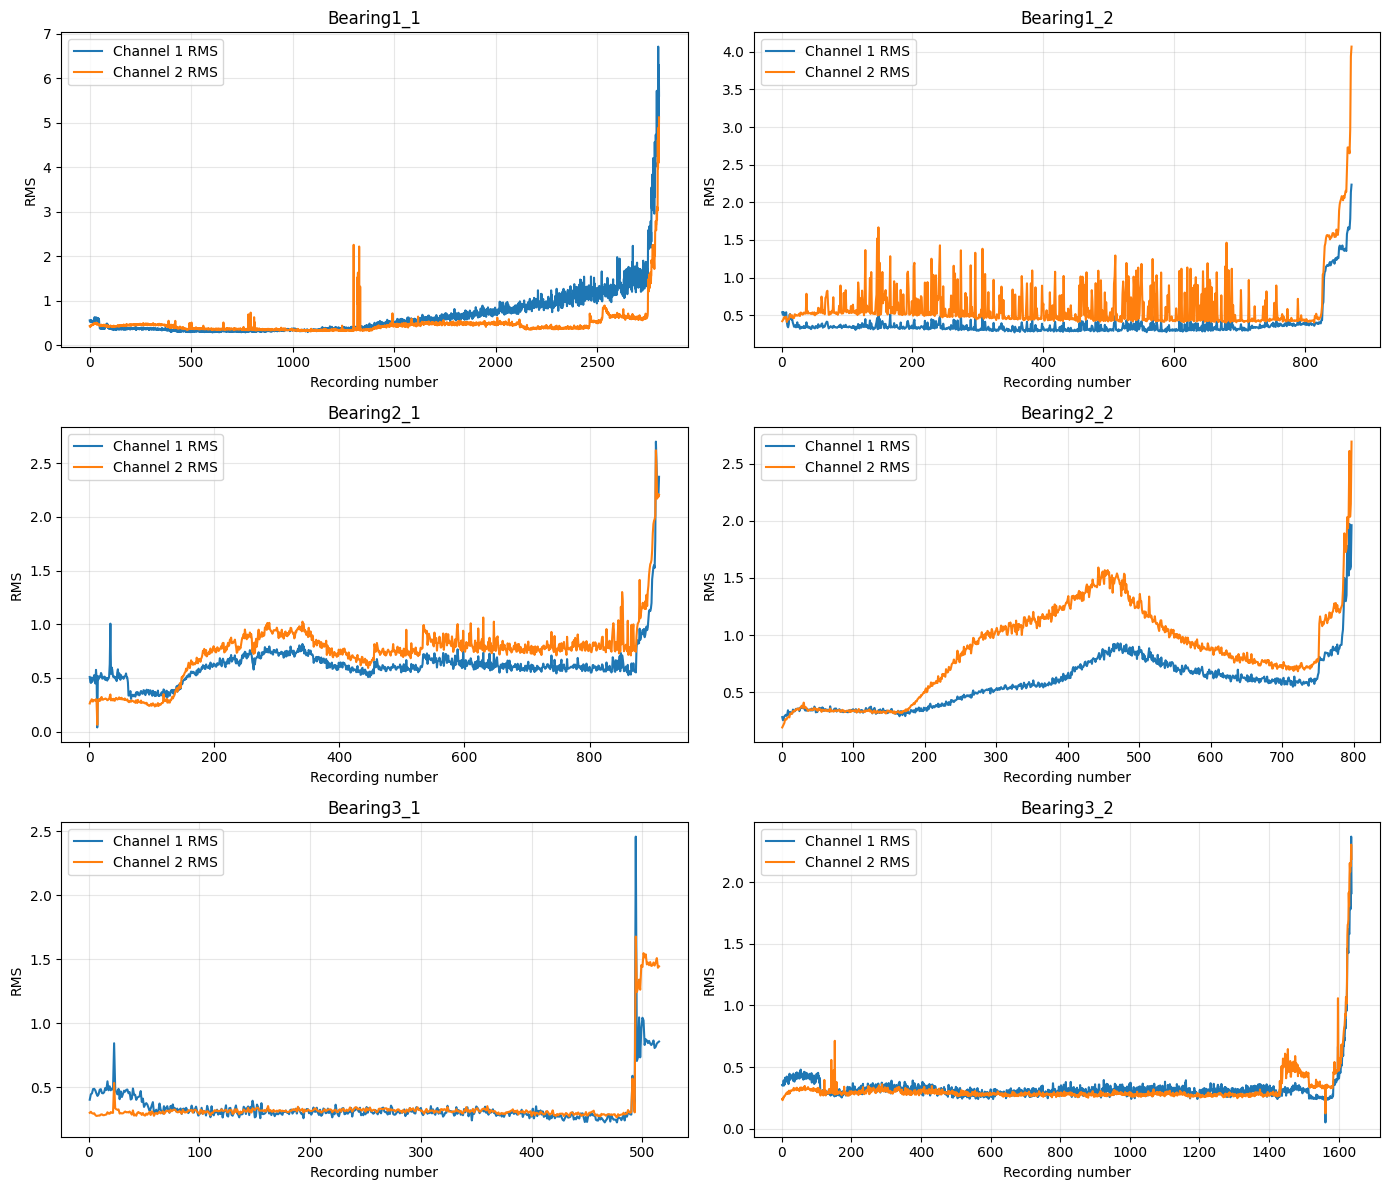

In [ ]:
import matplotlib.pyplot as plt

print("Dataset shape:", features_df.shape)
print("\nColumns:")
print(features_df.columns.tolist())

print("\nFeature summary:")
display(
    features_df[
        ["ch1_rms", "ch2_rms", "ch1_kurtosis", "ch2_kurtosis", "RUL_seconds"]
    ].describe().round(3)
)

fig, axes = plt.subplots(3, 2, figsize=(14, 12))

for ax, (bearing, data) in zip(
    axes.flat, features_df.groupby("bearing", sort=True)
):
    data = data.sort_values("recording_no")
    ax.plot(data["recording_no"], data["ch1_rms"], label="Channel 1 RMS")
    ax.plot(data["recording_no"], data["ch2_rms"], label="Channel 2 RMS")
    ax.set_title(bearing)
    ax.set_xlabel("Recording number")
    ax.set_ylabel("RMS")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
from sklearn.model_selection import train_test_split

# Hold out complete bearings for validation
all_bearings = sorted(features_df["bearing"].unique())

train_bearings = [
    b for b in all_bearings
    if b not in ["Bearing2_2", "Bearing3_1"]
]
val_bearings = ["Bearing2_2", "Bearing3_1"]

train_df = features_df[
    features_df["bearing"].isin(train_bearings)
].copy()

val_df = features_df[
    features_df["bearing"].isin(val_bearings)
].copy()

print("Training bearings:", train_bearings)
print("Validation bearings:", val_bearings)
print("Training rows:", len(train_df))
print("Validation rows:", len(val_df))

print("\nTraining RUL ranges:")
display(train_df.groupby("bearing")["RUL_seconds"].agg(["min", "max"]))

print("\nValidation RUL ranges:")
display(val_df.groupby("bearing")["RUL_seconds"].agg(["min", "max"]))

Training bearings: ['Bearing1_1', 'Bearing1_2', 'Bearing2_1', 'Bearing3_2']
Validation bearings: ['Bearing2_2', 'Bearing3_1']
Training rows: 6222
Validation rows: 1312

Training RUL ranges:


,min,max
bearing,,
Bearing1_1,0,28020
Bearing1_2,0,8700
Bearing2_1,0,9100
Bearing3_2,0,16360



Validation RUL ranges:


,min,max
bearing,,
Bearing2_2,0,7960
Bearing3_1,0,5140


In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# 1. Select vibration features and target
feature_cols = [
    "ch1_rms", "ch1_std", "ch1_mean_abs",
    "ch1_peak", "ch1_ptp", "ch1_kurtosis",
    "ch2_rms", "ch2_std", "ch2_mean_abs",
    "ch2_peak", "ch2_ptp", "ch2_kurtosis"
]

target_col = "RUL_seconds"

# 2. Create training and validation datasets
X_train = train_df[feature_cols].copy()
y_train = train_df[target_col].copy()

X_val = val_df[feature_cols].copy()
y_val = val_df[target_col].copy()

# 3. Check for missing or infinite values
for name, data in [
    ("X_train", X_train),
    ("X_val", X_val),
    ("y_train", y_train),
    ("y_val", y_val)
]:
    values = data.to_numpy(dtype=float)
    print(
        f"{name}: missing={np.isnan(values).sum()}, "
        f"infinite={np.isinf(values).sum()}"
    )

# 4. Replace infinite values with NaN and impute using training medians
X_train = X_train.replace([np.inf, -np.inf], np.nan)
X_val = X_val.replace([np.inf, -np.inf], np.nan)

medians = X_train.median()
X_train = X_train.fillna(medians)
X_val = X_val.fillna(medians)

# 5. Scale features using training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)

# 6. Verify the prepared data
print("\n=== PREPARED DATA ===")
print("Training bearings:", train_bearings)
print("Validation bearings:", val_bearings)
print("Training input shape:", X_train_scaled.shape)
print("Training target shape:", y_train.shape)
print("Validation input shape:", X_val_scaled.shape)
print("Validation target shape:", y_val.shape)

print("\nTarget statistics:")
print("Training RUL range:", y_train.min(), "to", y_train.max())
print("Validation RUL range:", y_val.min(), "to", y_val.max())

print("\nAll scaled training features finite:",
      np.isfinite(X_train_scaled).all())
print("All scaled validation features finite:",
      np.isfinite(X_val_scaled).all())
print("All targets finite:",
      np.isfinite(y_train.to_numpy()).all()
      and np.isfinite(y_val.to_numpy()).all())

X_train: missing=0, infinite=0
X_val: missing=0, infinite=0
y_train: missing=0, infinite=0
y_val: missing=0, infinite=0

=== PREPARED DATA ===
Training bearings: ['Bearing1_1', 'Bearing1_2', 'Bearing2_1', 'Bearing3_2']
Validation bearings: ['Bearing2_2', 'Bearing3_1']
Training input shape: (6222, 12)
Training target shape: (6222,)
Validation input shape: (1312, 12)
Validation target shape: (1312,)

Target statistics:
Training RUL range: 0 to 28020
Validation RUL range: 0 to 7960

All scaled training features finite: True
All scaled validation features finite: True
All targets finite: True



Training Results
MAE:  5273.46 seconds (87.89 minutes)
RMSE: 6619.56 seconds (110.33 minutes)
R²:   0.1905

Validation Results
MAE:  6869.98 seconds (114.50 minutes)
RMSE: 7630.85 seconds (127.18 minutes)
R²:   -11.7775

=== BASELINE SUMMARY ===


,Dataset,MAE,RMSE,R2
0,Training,5273.455,6619.562,0.191
1,Validation,6869.979,7630.846,-11.778


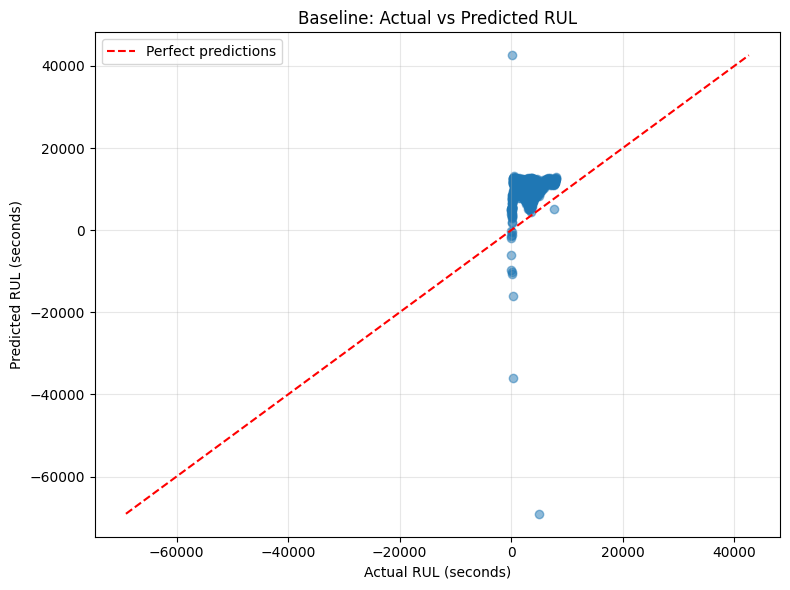

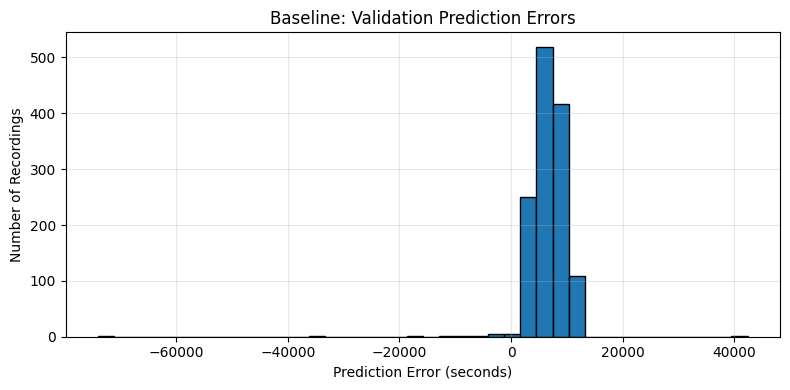

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# 1. Train baseline model
baseline_model = LinearRegression()
baseline_model.fit(X_train_scaled, y_train)

# 2. Predict RUL on training and validation sets
train_pred = baseline_model.predict(X_train_scaled)
val_pred = baseline_model.predict(X_val_scaled)

# 3. Calculate evaluation metrics
def evaluate_model(y_true, y_pred, dataset_name):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)

    print(f"\n{dataset_name} Results")
    print(f"MAE:  {mae:.2f} seconds ({mae / 60:.2f} minutes)")
    print(f"RMSE: {rmse:.2f} seconds ({rmse / 60:.2f} minutes)")
    print(f"R²:   {r2:.4f}")

    return {"Dataset": dataset_name, "MAE": mae, "RMSE": rmse, "R2": r2}

train_metrics = evaluate_model(y_train, train_pred, "Training")
val_metrics = evaluate_model(y_val, val_pred, "Validation")

results_df = pd.DataFrame([train_metrics, val_metrics])
print("\n=== BASELINE SUMMARY ===")
display(results_df.round(3))

# 4. Plot actual versus predicted RUL for validation data
plt.figure(figsize=(8, 6))
plt.scatter(y_val, val_pred, alpha=0.5)
max_value = max(y_val.max(), val_pred.max())
min_value = min(y_val.min(), val_pred.min())
plt.plot([min_value, max_value], [min_value, max_value], "r--",
         label="Perfect predictions")
plt.xlabel("Actual RUL (seconds)")
plt.ylabel("Predicted RUL (seconds)")
plt.title("Baseline: Actual vs Predicted RUL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Plot prediction errors
errors = val_pred - y_val.to_numpy()

plt.figure(figsize=(8, 4))
plt.hist(errors, bins=40, edgecolor="black")
plt.xlabel("Prediction Error (seconds)")
plt.ylabel("Number of Recordings")
plt.title("Baseline: Validation Prediction Errors")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

=== RANDOM FOREST RESULTS ===

Training:
MAE (seconds): 889.871
RMSE (seconds): 1600.495
R2: 0.953

Validation:
MAE (seconds): 5807.857
RMSE (seconds): 7210.213
R2: -10.408

=== MODEL COMPARISON ===


,Model,Dataset,MAE,RMSE,R2
0,Linear Regression,Validation,6869.979,7630.846,-11.778
1,Random Forest,Validation,5807.857,7210.213,-10.408



=== FEATURE IMPORTANCE ===


,Feature,Importance
5,ch1_kurtosis,0.326140
8,ch2_mean_abs,0.164134
6,ch2_rms,0.141585
7,ch2_std,0.133728
1,ch1_std,0.097195
2,ch1_mean_abs,0.074252
0,ch1_rms,0.020106
11,ch2_kurtosis,0.019262
4,ch1_ptp,0.008340
10,ch2_ptp,0.006165


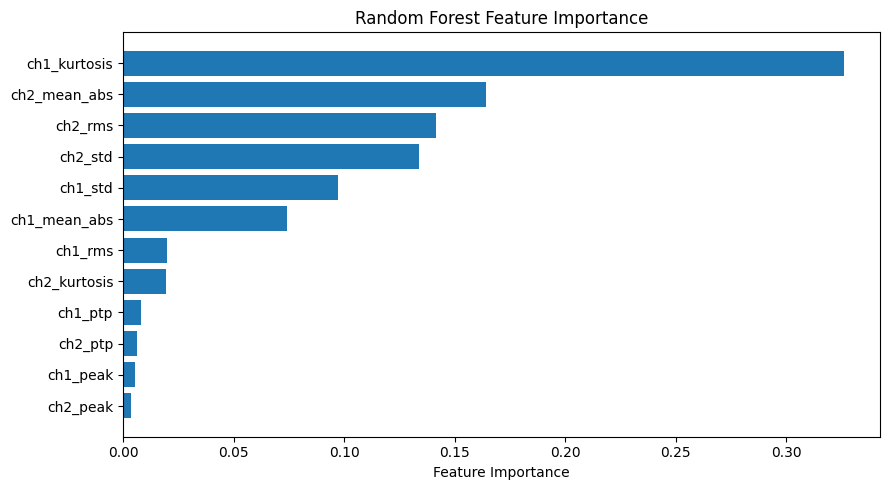

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Train Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=15,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_scaled, y_train)

# Predictions
rf_train_pred = rf_model.predict(X_train_scaled)
rf_val_pred = rf_model.predict(X_val_scaled)

# Evaluation
def calculate_metrics(y_true, y_pred):
    return {
        "MAE (seconds)": mean_absolute_error(y_true, y_pred),
        "RMSE (seconds)": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred)
    }

rf_train_metrics = calculate_metrics(y_train, rf_train_pred)
rf_val_metrics = calculate_metrics(y_val, rf_val_pred)

print("=== RANDOM FOREST RESULTS ===")
print("\nTraining:")
for metric, value in rf_train_metrics.items():
    print(f"{metric}: {value:.3f}")

print("\nValidation:")
for metric, value in rf_val_metrics.items():
    print(f"{metric}: {value:.3f}")

# Compare with Linear Regression
comparison_df = pd.DataFrame([
    {
        "Model": "Linear Regression",
        "Dataset": "Validation",
        "MAE": val_metrics["MAE"],
        "RMSE": val_metrics["RMSE"],
        "R2": val_metrics["R2"]
    },
    {
        "Model": "Random Forest",
        "Dataset": "Validation",
        "MAE": rf_val_metrics["MAE (seconds)"],
        "RMSE": rf_val_metrics["RMSE (seconds)"],
        "R2": rf_val_metrics["R2"]
    }
])

print("\n=== MODEL COMPARISON ===")
display(comparison_df.round(3))

# Feature importance
importance_df = pd.DataFrame({
    "Feature": feature_cols,
    "Importance": rf_model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n=== FEATURE IMPORTANCE ===")
display(importance_df)

plt.figure(figsize=(9, 5))
plt.barh(importance_df["Feature"], importance_df["Importance"])
plt.gca().invert_yaxis()
plt.xlabel("Feature Importance")
plt.title("Random Forest Feature Importance")
plt.tight_layout()
plt.show()

=== RANDOM FOREST: PER-BEARING VALIDATION ===


,Bearing,Recordings,Actual RUL range (sec),MAE (sec),RMSE (sec),R²
0,Bearing2_2,797,0–7960,3825.507,5567.021,-4.855
1,Bearing3_1,515,0–5140,8875.687,9191.255,-37.222


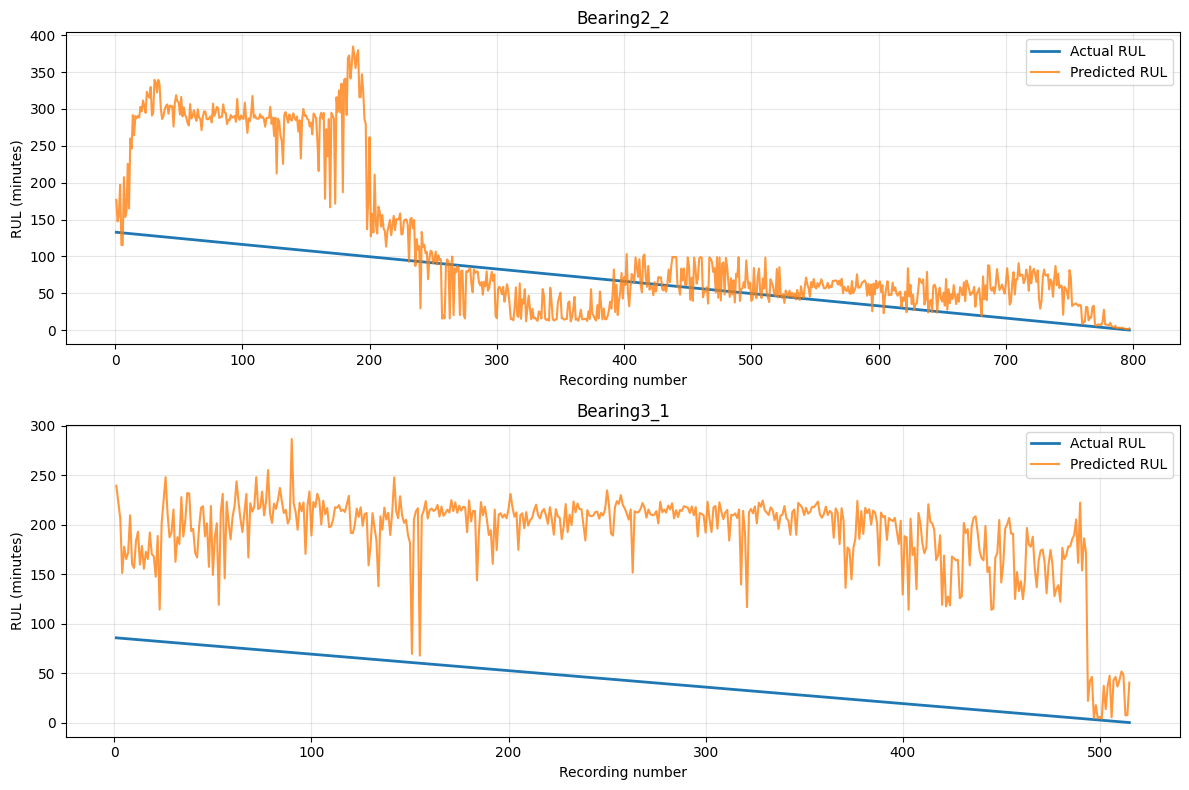

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate Random Forest separately on each validation bearing
bearing_results = []

for bearing in val_bearings:
    mask = val_df["bearing"].to_numpy() == bearing

    actual = y_val.to_numpy()[mask]
    predicted = rf_val_pred[mask]

    bearing_results.append({
        "Bearing": bearing,
        "Recordings": len(actual),
        "Actual RUL range (sec)": f"{actual.min()}–{actual.max()}",
        "MAE (sec)": mean_absolute_error(actual, predicted),
        "RMSE (sec)": np.sqrt(mean_squared_error(actual, predicted)),
        "R²": r2_score(actual, predicted)
    })

bearing_results_df = pd.DataFrame(bearing_results)

print("=== RANDOM FOREST: PER-BEARING VALIDATION ===")
display(bearing_results_df.round(3))

# Plot actual and predicted RUL against recording number
fig, axes = plt.subplots(len(val_bearings), 1, figsize=(12, 8))
axes = np.atleast_1d(axes)

for ax, bearing in zip(axes, val_bearings):
    data = val_df[val_df["bearing"] == bearing].sort_values("recording_no")
    indices = data.index

    # Align predictions with the original validation rows
    positions = val_df.index.get_indexer(indices)
    predictions = rf_val_pred[positions]

    ax.plot(
        data["recording_no"],
        data["RUL_seconds"] / 60,
        label="Actual RUL",
        linewidth=2
    )
    ax.plot(
        data["recording_no"],
        predictions / 60,
        label="Predicted RUL",
        alpha=0.8
    )

    ax.set_title(bearing)
    ax.set_xlabel("Recording number")
    ax.set_ylabel("RUL (minutes)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Training sequence shape: (6106, 30, 12)
Validation sequence shape: (1254, 30, 12)
Training target shape: (6106,)
Validation target shape: (1254,)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 30, 32)         │         1,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling1d (MaxPooling1D)    │ (None, 15, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 15, 64)         │         6,208 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d        │ (None, 64)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,273 (40.13 KB)

 Trainable params: 10,273 (40.13 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 9s 39ms/step - loss: 143419408.0000 - mae: 9510.9541 - val_loss: 10734197.0000 - val_mae: 2692.7844
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 85115376.0000 - mae: 7054.8584 - val_loss: 59115112.0000 - val_mae: 6056.6680
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 50870252.0000 - mae: 5665.5615 - val_loss: 55069964.0000 - val_mae: 5763.6196
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 42497612.0000 - mae: 5104.8950 - val_loss: 55200928.0000 - val_mae: 5823.8481
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 33049868.0000 - mae: 4521.2480 - val_loss: 59225728.0000 - val_mae: 6958.8413
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 29074704.0000 - mae: 4289.6064 - val_loss: 59334048.0000 - val_mae: 7218.8447
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 27876158.0000 - mae: 4124.0073 - val_loss: 56584272.0000 - val_mae: 6960.0425
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/s

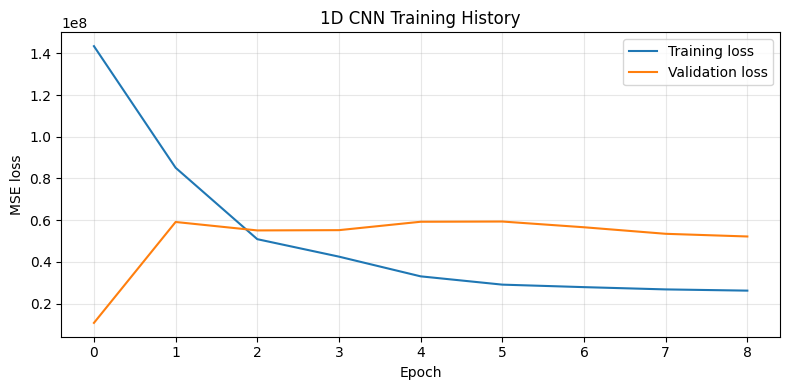

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# 1. Create sequences separately for each bearing
WINDOW_SIZE = 30

def create_sequences(df, scaled_features, window_size=30):
    X_seq, y_seq, bearing_seq = [], [], []

    # Map each row to its position in the scaled feature array
    row_positions = {idx: pos for pos, idx in enumerate(df.index)}

    for bearing, group in df.groupby("bearing", sort=True):
        group = group.sort_values("recording_no")
        positions = [row_positions[idx] for idx in group.index]

        bearing_features = scaled_features[positions]
        bearing_rul = group["RUL_seconds"].to_numpy()

        for end in range(window_size - 1, len(group)):
            start = end - window_size + 1

            X_seq.append(bearing_features[start:end + 1])
            y_seq.append(bearing_rul[end])
            bearing_seq.append(bearing)

    return (
        np.asarray(X_seq, dtype=np.float32),
        np.asarray(y_seq, dtype=np.float32),
        np.asarray(bearing_seq)
    )

X_train_seq, y_train_seq, train_seq_bearings = create_sequences(
    train_df, X_train_scaled, WINDOW_SIZE
)

X_val_seq, y_val_seq, val_seq_bearings = create_sequences(
    val_df, X_val_scaled, WINDOW_SIZE
)

print("Training sequence shape:", X_train_seq.shape)
print("Validation sequence shape:", X_val_seq.shape)
print("Training target shape:", y_train_seq.shape)
print("Validation target shape:", y_val_seq.shape)

# 2. Build the 1D CNN
cnn_model = keras.Sequential([
    layers.Input(shape=(WINDOW_SIZE, len(feature_cols))),

    layers.Conv1D(32, kernel_size=5, padding="same", activation="relu"),
    layers.MaxPooling1D(pool_size=2),

    layers.Conv1D(64, kernel_size=3, padding="same", activation="relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1)
])

cnn_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="mse",
    metrics=["mae"]
)

cnn_model.summary()

# 3. Train with early stopping
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history = cnn_model.fit(
    X_train_seq,
    y_train_seq,
    validation_data=(X_val_seq, y_val_seq),
    epochs=50,
    batch_size=64,
    callbacks=[early_stopping],
    verbose=1
)

# 4. Evaluate the CNN
cnn_val_pred = cnn_model.predict(X_val_seq, verbose=0).flatten()

cnn_results = {
    "Model": "1D CNN",
    "MAE": mean_absolute_error(y_val_seq, cnn_val_pred),
    "RMSE": np.sqrt(mean_squared_error(y_val_seq, cnn_val_pred)),
    "R2": r2_score(y_val_seq, cnn_val_pred)
}

print("\n=== CNN VALIDATION RESULTS ===")
for metric, value in cnn_results.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.3f}")

# 5. Plot training and validation loss
plt.figure(figsize=(8, 4))
plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("1D CNN Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Overall CNN validation results
MAE:  2692.78 seconds
RMSE: 3276.31 seconds
R²:   -1.5287

Bearing2_2
MAE:  3404.89 seconds
RMSE: 3900.81 seconds
R²:   -2.0958

Bearing3_1
MAE:  1567.48 seconds
RMSE: 1910.86 seconds
R²:   -0.8551


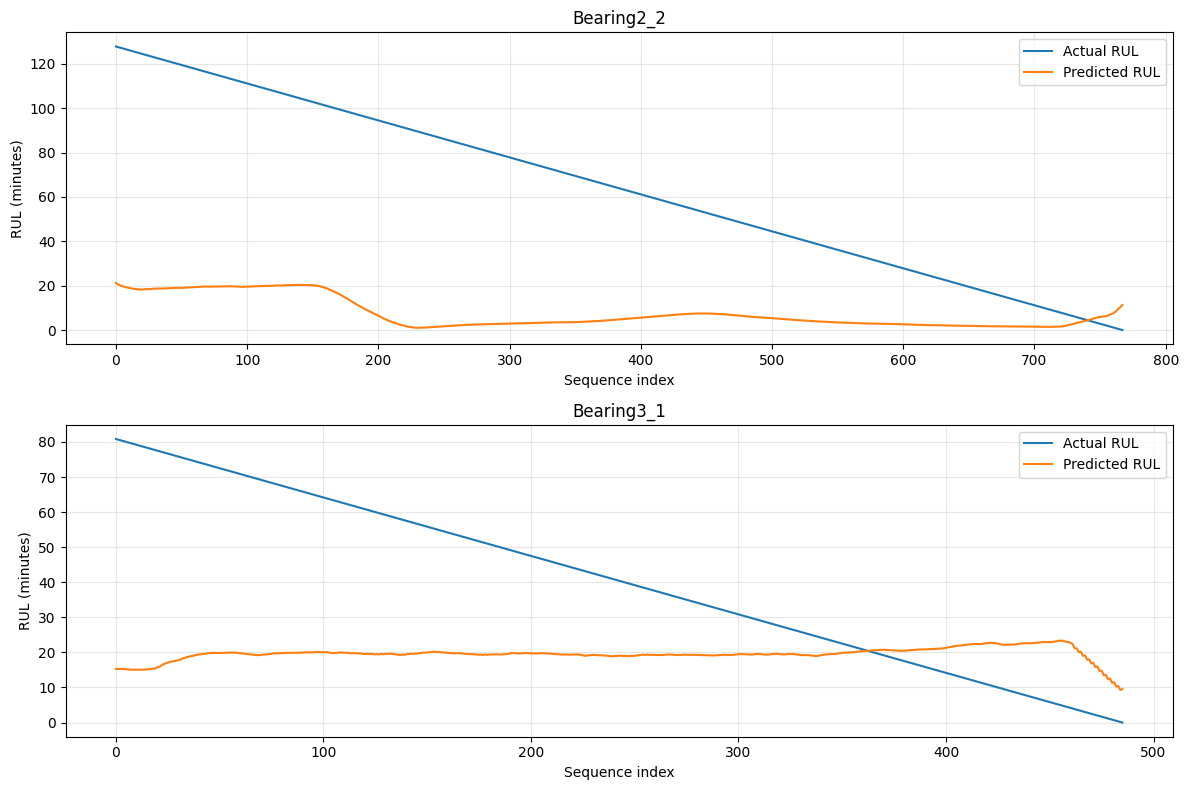

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Evaluate the restored best CNN model
cnn_val_pred = cnn_model.predict(X_val_seq, verbose=0).flatten()

print("Overall CNN validation results")
print(f"MAE:  {mean_absolute_error(y_val_seq, cnn_val_pred):.2f} seconds")
print(f"RMSE: {np.sqrt(mean_squared_error(y_val_seq, cnn_val_pred)):.2f} seconds")
print(f"R²:   {r2_score(y_val_seq, cnn_val_pred):.4f}")

# Evaluate and plot each bearing separately
fig, axes = plt.subplots(len(val_bearings), 1, figsize=(12, 8))
axes = np.atleast_1d(axes)

for ax, bearing in zip(axes, val_bearings):
    mask = val_seq_bearings == bearing

    actual = y_val_seq[mask]
    predicted = cnn_val_pred[mask]

    print(f"\n{bearing}")
    print(f"MAE:  {mean_absolute_error(actual, predicted):.2f} seconds")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.2f} seconds")
    print(f"R²:   {r2_score(actual, predicted):.4f}")

    ax.plot(actual / 60, label="Actual RUL")
    ax.plot(predicted / 60, label="Predicted RUL")
    ax.set_title(bearing)
    ax.set_xlabel("Sequence index")
    ax.set_ylabel("RUL (minutes)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Normalized training target range: 0.0 to 1.0
Normalized validation target range: 0.0 to 1.0
Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 26ms/step - loss: 0.0553 - mae: 0.1906 - val_loss: 0.0571 - val_mae: 0.1956
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0381 - mae: 0.1508 - val_loss: 0.0504 - val_mae: 0.1800
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0315 - mae: 0.1366 - val_loss: 0.0466 - val_mae: 0.1754
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0282 - mae: 0.1283 - val_loss: 0.0449 - val_mae: 0.1716
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0257 - mae: 0.1213 - val_loss: 0.0452 - val_mae: 0.1748
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0239 - mae: 0.1160 - val_loss: 0.0460 - val_mae: 0.1741
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0225 - mae: 0.1117 - val_loss: 0.0464 - val_mae: 0.1787
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0211 - mae: 0.1070 - val_loss: 0.04

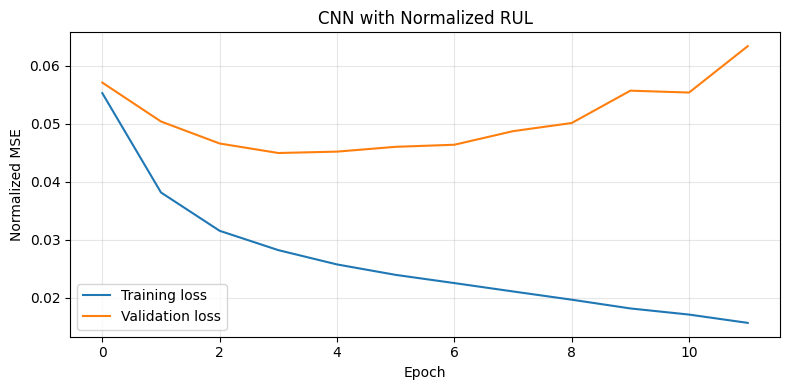

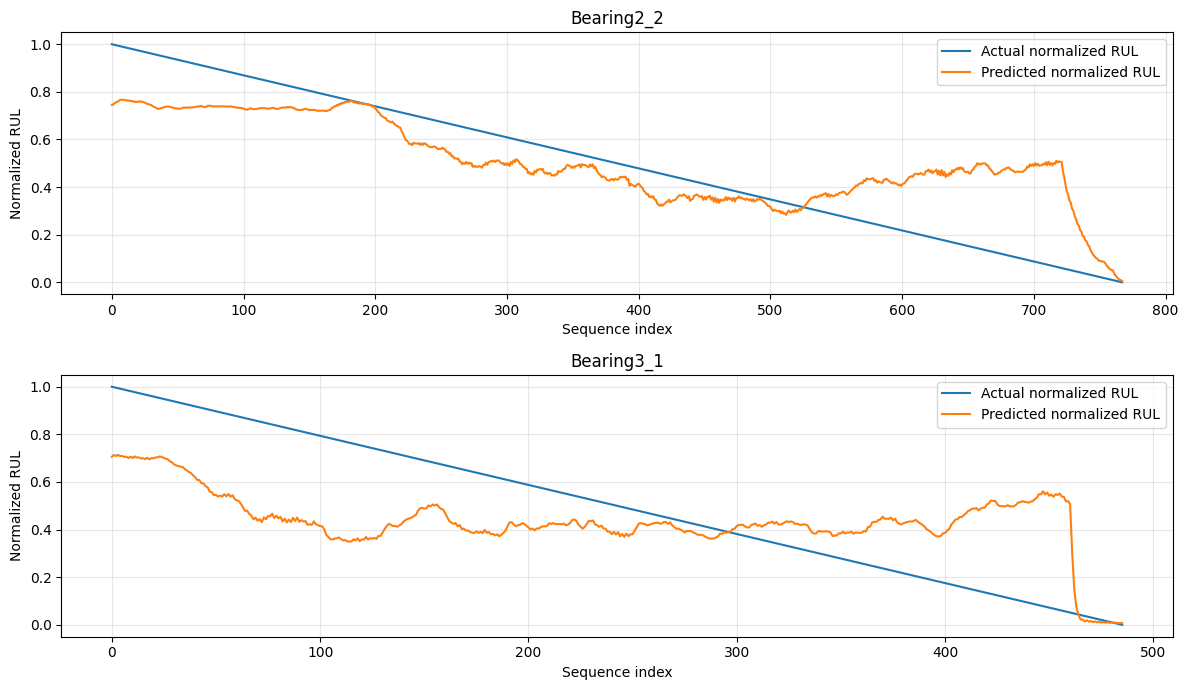

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# 1. Normalize RUL separately for each bearing
def normalize_rul(y, bearing_ids):
    y_norm = np.zeros_like(y, dtype=np.float32)

    for bearing in np.unique(bearing_ids):
        mask = bearing_ids == bearing
        max_rul = np.max(y[mask])

        if max_rul > 0:
            y_norm[mask] = y[mask] / max_rul

    return y_norm

y_train_norm = normalize_rul(y_train_seq, train_seq_bearings)
y_val_norm = normalize_rul(y_val_seq, val_seq_bearings)

print("Normalized training target range:",
      y_train_norm.min(), "to", y_train_norm.max())
print("Normalized validation target range:",
      y_val_norm.min(), "to", y_val_norm.max())

# 2. Build a fresh CNN
cnn_norm = keras.Sequential([
    layers.Input(shape=(WINDOW_SIZE, len(feature_cols))),

    layers.Conv1D(32, 5, padding="same", activation="relu"),
    layers.MaxPooling1D(2),
    layers.Conv1D(64, 3, padding="same", activation="relu"),
    layers.GlobalAveragePooling1D(),

    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),
    layers.Dense(1, activation="sigmoid")
])

cnn_norm.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

early_stop_norm = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

history_norm = cnn_norm.fit(
    X_train_seq,
    y_train_norm,
    validation_data=(X_val_seq, y_val_norm),
    epochs=50,
    batch_size=64,
    callbacks=[early_stop_norm],
    verbose=1
)

# 3. Evaluate normalized predictions
pred_norm = cnn_norm.predict(X_val_seq, verbose=0).flatten()

print("\n=== NORMALIZED CNN RESULTS ===")
print("Normalized MAE:",
      round(mean_absolute_error(y_val_norm, pred_norm), 4))
print("Normalized RMSE:",
      round(np.sqrt(mean_squared_error(y_val_norm, pred_norm)), 4))
print("Normalized R²:",
      round(r2_score(y_val_norm, pred_norm), 4))

# 4. Plot training history
plt.figure(figsize=(8, 4))
plt.plot(history_norm.history["loss"], label="Training loss")
plt.plot(history_norm.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("CNN with Normalized RUL")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 5. Plot normalized actual vs predicted RUL
fig, axes = plt.subplots(2, 1, figsize=(12, 7))

for ax, bearing in zip(axes, val_bearings):
    mask = val_seq_bearings == bearing

    ax.plot(y_val_norm[mask], label="Actual normalized RUL")
    ax.plot(pred_norm[mask], label="Predicted normalized RUL")

    ax.set_title(bearing)
    ax.set_xlabel("Sequence index")
    ax.set_ylabel("Normalized RUL")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 30, 64)         │        19,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 30, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 33,217 (129.75 KB)

 Trainable params: 33,217 (129.75 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.0549 - mae: 0.1910 - val_loss: 0.0469 - val_mae: 0.1776
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 9ms/step - loss: 0.0353 - mae: 0.1489 - val_loss: 0.0426 - val_mae: 0.1798
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0272 - mae: 0.1283 - val_loss: 0.0437 - val_mae: 0.1792
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0228 - mae: 0.1180 - val_loss: 0.0560 - val_mae: 0.2022
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0196 - mae: 0.1082 - val_loss: 0.0565 - val_mae: 0.2059
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0171 - mae: 0.0997 - val_loss: 0.0538 - val_mae: 0.1957
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0149 - mae: 0.0906 - val_loss: 0.0552 - val_mae: 0.2049
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0121 - mae: 0.0810 - val_loss: 0.0595 - val_mae: 0.2132
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0099 - ma

,Model,MAE,RMSE,R2
0,1D CNN,0.1716,0.2120,0.4624
1,LSTM,0.1798,0.2063,0.4909


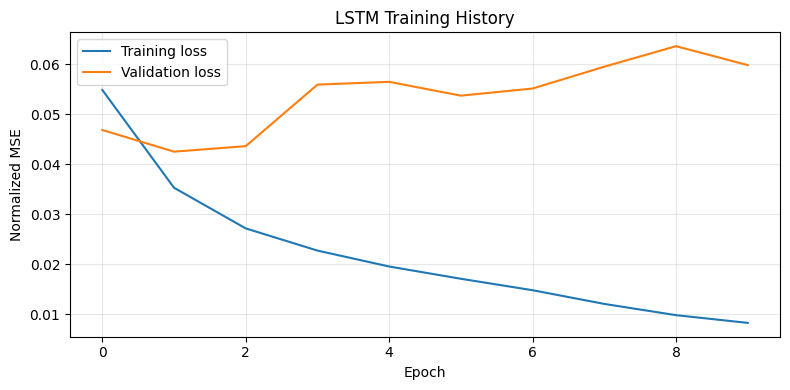

In [ ]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# 1. Build the LSTM
lstm_model = keras.Sequential([
    layers.Input(shape=(WINDOW_SIZE, len(feature_cols))),

    layers.LSTM(64, return_sequences=True),
    layers.Dropout(0.2),

    layers.LSTM(32),
    layers.Dense(32, activation="relu"),
    layers.Dropout(0.2),

    # Predict normalized RUL between 0 and 1
    layers.Dense(1, activation="sigmoid")
])

lstm_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

lstm_model.summary()

# 2. Train with early stopping
lstm_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

lstm_history = lstm_model.fit(
    X_train_seq,
    y_train_norm,
    validation_data=(X_val_seq, y_val_norm),
    epochs=50,
    batch_size=64,
    callbacks=[lstm_early_stop],
    verbose=1
)

# 3. Predict normalized RUL
lstm_val_pred = lstm_model.predict(
    X_val_seq, verbose=0
).flatten()

# 4. Evaluate
lstm_results = {
    "Model": "LSTM",
    "MAE": mean_absolute_error(y_val_norm, lstm_val_pred),
    "RMSE": np.sqrt(mean_squared_error(y_val_norm, lstm_val_pred)),
    "R2": r2_score(y_val_norm, lstm_val_pred)
}

print("\n=== LSTM VALIDATION RESULTS ===")
for metric, value in lstm_results.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.4f}")

# 5. Compare with normalized CNN
cnn_normalized_results = {
    "Model": "1D CNN",
    "MAE": mean_absolute_error(y_val_norm, pred_norm),
    "RMSE": np.sqrt(mean_squared_error(y_val_norm, pred_norm)),
    "R2": r2_score(y_val_norm, pred_norm)
}

comparison = pd.DataFrame([
    cnn_normalized_results,
    lstm_results
])

print("\n=== NORMALIZED MODEL COMPARISON ===")
display(comparison.round(4))

# 6. Plot training history
plt.figure(figsize=(8, 4))
plt.plot(lstm_history.history["loss"], label="Training loss")
plt.plot(lstm_history.history["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("Normalized MSE")
plt.title("LSTM Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# 7. Plot predictions by

Global RUL scale: 27730.0 seconds
Training target range: 0.0 to 1.0
Validation target range: 0.0 to 0.27659574

========== Training CNN ==========
Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 5s 24ms/step - loss: 0.0414 - mae: 0.1587 - val_loss: 0.0559 - val_mae: 0.2062
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0199 - mae: 0.1026 - val_loss: 0.0508 - val_mae: 0.1944
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0154 - mae: 0.0877 - val_loss: 0.0470 - val_mae: 0.1859
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0139 - mae: 0.0835 - val_loss: 0.0417 - val_mae: 0.1763
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0120 - mae: 0.0772 - val_loss: 0.0398 - val_mae: 0.1711
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - loss: 0.0108 - mae: 0.0730 - val_loss: 0.0393 - val_mae: 0.1701
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - loss: 0.0099 - mae: 0.0694 - val_loss: 0.0378 - val_mae: 0.1663
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 0s

,Model,MAE (seconds),RMSE (seconds),R2
0,1D CNN,4388.278,5142.558,-5.230
1,LSTM,3703.970,4628.823,-4.047


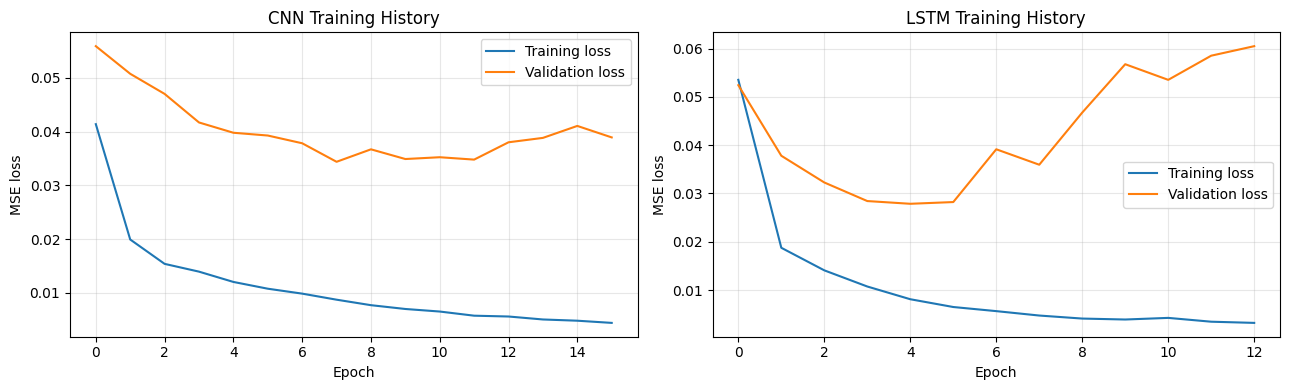

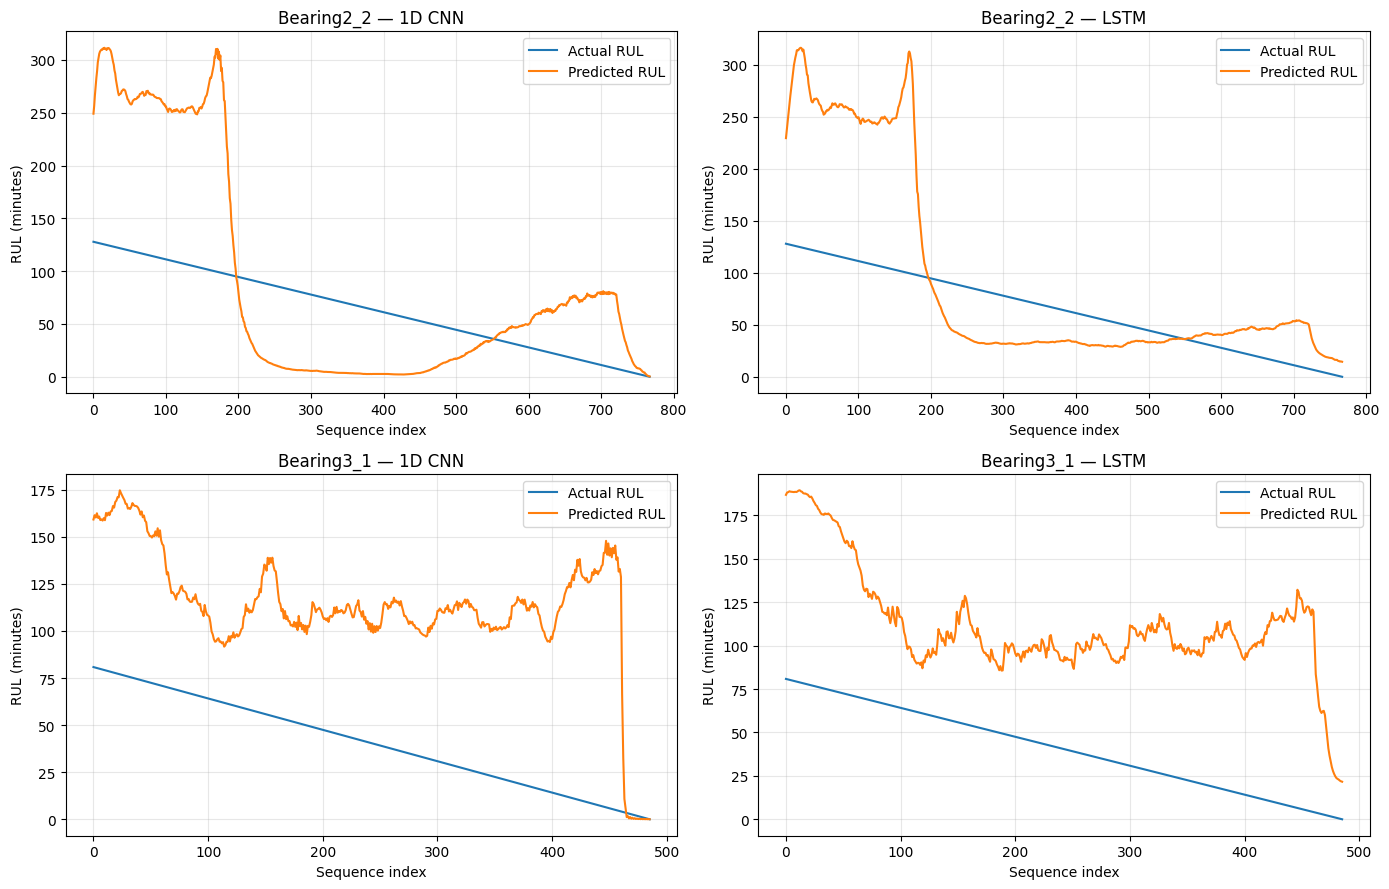

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# ============================================================
# 1. Normalize all targets using ONE training-derived scale
# ============================================================

RUL_SCALE = float(np.max(y_train_seq))

y_train_global = y_train_seq / RUL_SCALE
y_val_global = y_val_seq / RUL_SCALE

print("Global RUL scale:", RUL_SCALE, "seconds")
print("Training target range:",
      y_train_global.min(), "to", y_train_global.max())
print("Validation target range:",
      y_val_global.min(), "to", y_val_global.max())

# ============================================================
# 2. Define fresh CNN and LSTM models
# ============================================================

def build_cnn():
    model = keras.Sequential([
        layers.Input(shape=(WINDOW_SIZE, len(feature_cols))),
        layers.Conv1D(32, 5, padding="same", activation="relu"),
        layers.MaxPooling1D(2),
        layers.Conv1D(64, 3, padding="same", activation="relu"),
        layers.GlobalAveragePooling1D(),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0003),
        loss="mse",
        metrics=["mae"]
    )
    return model


def build_lstm():
    model = keras.Sequential([
        layers.Input(shape=(WINDOW_SIZE, len(feature_cols))),
        layers.LSTM(64, return_sequences=True),
        layers.Dropout(0.2),
        layers.LSTM(32),
        layers.Dense(32, activation="relu"),
        layers.Dropout(0.2),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0003),
        loss="mse",
        metrics=["mae"]
    )
    return model


# ============================================================
# 3. Train both models with identical targets and split
# ============================================================

def train_model(model, model_name):
    early_stop = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=8,
        restore_best_weights=True
    )

    print(f"\n========== Training {model_name} ==========")

    history = model.fit(
        X_train_seq,
        y_train_global,
        validation_data=(X_val_seq, y_val_global),
        epochs=50,
        batch_size=64,
        callbacks=[early_stop],
        verbose=1
    )

    return model, history


cnn_global, cnn_global_history = train_model(
    build_cnn(), "CNN"
)

lstm_global, lstm_global_history = train_model(
    build_lstm(), "LSTM"
)

# ============================================================
# 4. Convert predictions back to seconds and evaluate
# ============================================================

models = {
    "1D CNN": cnn_global,
    "LSTM": lstm_global
}

predictions_seconds = {}
results = []

for name, model in models.items():
    pred_scaled = model.predict(X_val_seq, verbose=0).flatten()
    pred_seconds = pred_scaled * RUL_SCALE

    predictions_seconds[name] = pred_seconds

    results.append({
        "Model": name,
        "MAE (seconds)": mean_absolute_error(
            y_val_seq, pred_seconds
        ),
        "RMSE (seconds)": np.sqrt(
            mean_squared_error(y_val_seq, pred_seconds)
        ),
        "R2": r2_score(y_val_seq, pred_seconds)
    })

results_df = pd.DataFrame(results)

print("\n========== VALIDATION RESULTS ==========")
display(results_df.round(3))

# ============================================================
# 5. Plot training histories
# ============================================================

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

for ax, name, history in [
    (axes[0], "CNN", cnn_global_history),
    (axes[1], "LSTM", lstm_global_history)
]:
    ax.plot(history.history["loss"], label="Training loss")
    ax.plot(history.history["val_loss"], label="Validation loss")
    ax.set_title(f"{name} Training History")
    ax.set_xlabel("Epoch")
    ax.set_ylabel("MSE loss")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

# ============================================================
# 6. Plot predictions for each validation bearing
# ============================================================

fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for row, bearing in enumerate(val_bearings):
    mask = val_seq_bearings == bearing
    actual_minutes = y_val_seq[mask] / 60

    for col, model_name in enumerate(["1D CNN", "LSTM"]):
        ax = axes[row, col]
        predicted_minutes = predictions_seconds[model_name][mask] / 60

        ax.plot(actual_minutes, label="Actual RUL")
        ax.plot(predicted_minutes, label="Predicted RUL")

        ax.set_title(f"{bearing} — {model_name}")
        ax.set_xlabel("Sequence index")
        ax.set_ylabel("RUL (minutes)")
        ax.legend()
        ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Training sequences: (6106, 30, 13)
Validation sequences: (1254, 30, 13)
Features per time step: 13


Model: "sequential_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_4 (LSTM)                   │ (None, 32)             │         5,888 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 32)             │         1,056 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_11 (Dense)                │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 6,977 (27.25 KB)

 Trainable params: 6,977 (27.25 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - loss: 0.0732 - mae: 0.2377 - val_loss: 0.1303 - val_mae: 0.3478
Epoch 2/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0231 - mae: 0.1183 - val_loss: 0.1085 - val_mae: 0.2633
Epoch 3/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0102 - mae: 0.0713 - val_loss: 0.1085 - val_mae: 0.2567
Epoch 4/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0076 - mae: 0.0626 - val_loss: 0.1149 - val_mae: 0.2612
Epoch 5/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0057 - mae: 0.0554 - val_loss: 0.1137 - val_mae: 0.2580
Epoch 6/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0045 - mae: 0.0496 - val_loss: 0.1151 - val_mae: 0.2583
Epoch 7/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0037 - mae: 0.0451 - val_loss: 0.1123 - val_mae: 0.2546
Epoch 8/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0033 - mae: 0.0422 - val_loss: 0.1199 - val_mae: 0.2626
Epoch 9/50
96/96 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0027 - mae:

,Model,MAE (seconds),RMSE (seconds),R2
0,1D CNN,4388.278,5142.558,-5.230
1,LSTM,3703.970,4628.823,-4.047
2,LSTM + elapsed time,7116.968,9135.367,-18.660


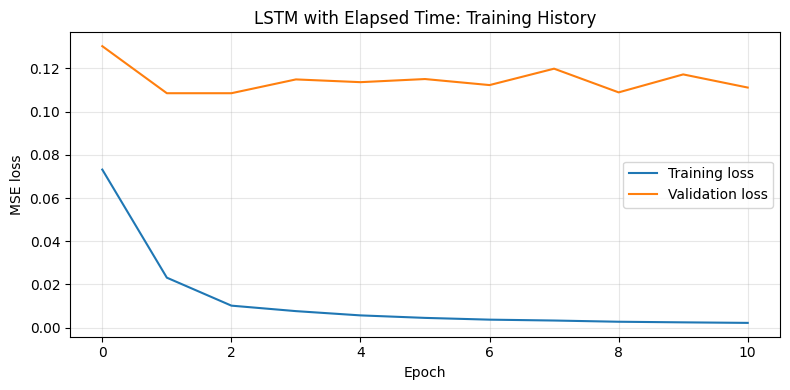

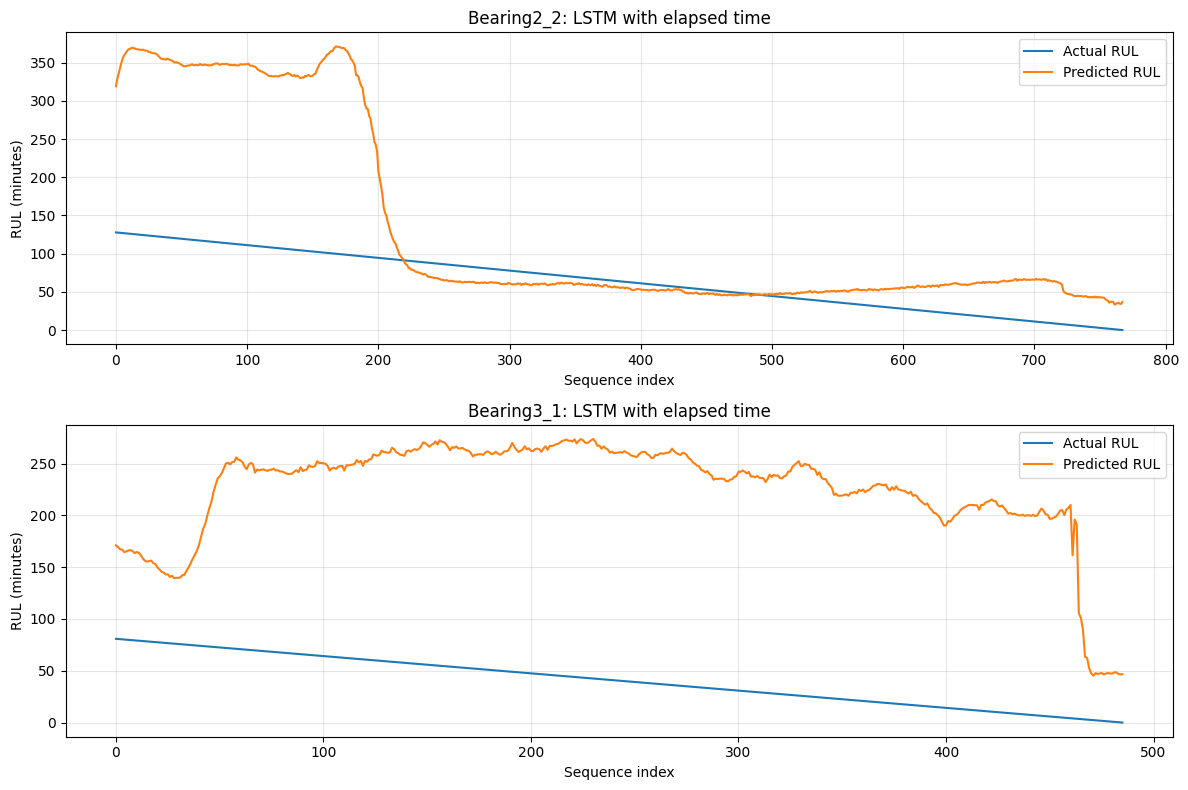

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# ============================================================
# 1. Add elapsed time to the vibration features
# ============================================================

age_feature_cols = feature_cols + ["elapsed_seconds"]

age_scaler = StandardScaler()

# Fit the input scaler only on the training bearings
X_train_age = age_scaler.fit_transform(
    train_df[age_feature_cols]
)

X_val_age = age_scaler.transform(
    val_df[age_feature_cols]
)

# Create sequences independently for each bearing
X_train_age_seq, y_train_age_seq, train_age_bearings = create_sequences(
    train_df, X_train_age, WINDOW_SIZE
)

X_val_age_seq, y_val_age_seq, val_age_bearings = create_sequences(
    val_df, X_val_age, WINDOW_SIZE
)

print("Training sequences:", X_train_age_seq.shape)
print("Validation sequences:", X_val_age_seq.shape)
print("Features per time step:", len(age_feature_cols))

# Targets are scaled using a single training-derived scale
RUL_SCALE = float(y_train_age_seq.max())

y_train_age_scaled = y_train_age_seq / RUL_SCALE
y_val_age_scaled = y_val_age_seq / RUL_SCALE

# ============================================================
# 2. Build an LSTM with 13 input features
# ============================================================

lstm_age_model = keras.Sequential([
    layers.Input(
        shape=(WINDOW_SIZE, len(age_feature_cols))
    ),

    layers.LSTM(32),
    layers.Dropout(0.2),

    layers.Dense(32, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

lstm_age_model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.0003),
    loss="mse",
    metrics=["mae"]
)

lstm_age_model.summary()

# ============================================================
# 3. Train with early stopping
# ============================================================

age_early_stop = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=8,
    restore_best_weights=True
)

lstm_age_history = lstm_age_model.fit(
    X_train_age_seq,
    y_train_age_scaled,
    validation_data=(X_val_age_seq, y_val_age_scaled),
    epochs=50,
    batch_size=64,
    callbacks=[age_early_stop],
    verbose=1
)

# ============================================================
# 4. Evaluate in seconds
# ============================================================

age_pred_scaled = lstm_age_model.predict(
    X_val_age_seq, verbose=0
).flatten()

age_pred_seconds = age_pred_scaled * RUL_SCALE

age_metrics = {
    "Model": "LSTM + elapsed time",
    "MAE (seconds)": mean_absolute_error(
        y_val_age_seq, age_pred_seconds
    ),
    "RMSE (seconds)": np.sqrt(
        mean_squared_error(y_val_age_seq, age_pred_seconds)
    ),
    "R2": r2_score(y_val_age_seq, age_pred_seconds)
}

print("\n=== LSTM WITH ELAPSED TIME ===")
for metric, value in age_metrics.items():
    if metric == "Model":
        print(f"{metric}: {value}")
    else:
        print(f"{metric}: {value:.3f}")

print("\n=== COMPARISON WITH PREVIOUS MODELS ===")
comparison_age = pd.concat(
    [results_df, pd.DataFrame([age_metrics])],
    ignore_index=True
)
display(comparison_age.round(3))

# ============================================================
# 5. Plot training history
# ============================================================

plt.figure(figsize=(8, 4))
plt.plot(lstm_age_history.history["loss"], label="Training loss")
plt.plot(
    lstm_age_history.history["val_loss"],
    label="Validation loss"
)
plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("LSTM with Elapsed Time: Training History")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ============================================================
# 6. Plot predictions by validation bearing
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

for ax, bearing in zip(axes, val_bearings):
    mask = val_age_bearings == bearing

    actual_minutes = y_val_age_seq[mask] / 60
    predicted_minutes = age_pred_seconds[mask] / 60

    ax.plot(actual_minutes, label="Actual RUL")
    ax.plot(predicted_minutes, label="Predicted RUL")

    ax.set_title(f"{bearing}: LSTM with elapsed time")
    ax.set_xlabel("Sequence index")
    ax.set_ylabel("RUL (minutes)")
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

Bearings: ['Bearing1_1', 'Bearing1_2', 'Bearing2_1', 'Bearing2_2', 'Bearing3_1', 'Bearing3_2']
Number of independent bearings: 6
Features per recording: 12
Sequence window: 30

Fold 1/6 — held-out: Bearing1_1
Training sequences: (4586, 30, 12)
Held-out sequences: (2774, 30, 12)
CNN: MAE=10735.8s, RMSE=11734.1s, R2=-1.147
LSTM: MAE=8982.3s, RMSE=11355.4s, R2=-1.011

Fold 2/6 — held-out: Bearing1_2
Training sequences: (6518, 30, 12)
Held-out sequences: (842, 30, 12)
CNN: MAE=7544.5s, RMSE=9079.9s, R2=-12.955
LSTM: MAE=5289.6s, RMSE=6132.0s, R2=-5.364

Fold 3/6 — held-out: Bearing2_1
Training sequences: (6478, 30, 12)
Held-out sequences: (882, 30, 12)
CNN: MAE=2274.0s, RMSE=2870.2s, R2=-0.271
LSTM: MAE=1661.5s, RMSE=2142.2s, R2=0.292

Fold 4/6 — held-out: Bearing2_2
Training sequences: (6592, 30, 12)
Held-out sequences: (768, 30, 12)
CNN: MAE=5230.1s, RMSE=6302.3s, R2=-7.081
LSTM: MAE=3545.0s, RMSE=4967.0s, R2=-4.019

Fold 5/6 — held-out: Bearing3_1
Training sequences: (6874, 30, 12)
Held

,Bearing,Model,Recordings,MAE (seconds),RMSE (seconds),R2
0,Bearing1_1,CNN,2774,10735.779,11734.088,-1.147
1,Bearing1_1,LSTM,2774,8982.336,11355.408,-1.011
2,Bearing1_2,CNN,842,7544.477,9079.886,-12.955
3,Bearing1_2,LSTM,842,5289.619,6131.955,-5.364
4,Bearing2_1,CNN,882,2274.047,2870.215,-0.271
5,Bearing2_1,LSTM,882,1661.482,2142.218,0.292
6,Bearing2_2,CNN,768,5230.149,6302.321,-7.081
7,Bearing2_2,LSTM,768,3544.967,4966.992,-4.019
8,Bearing3_1,CNN,486,5656.217,5932.917,-16.883
9,Bearing3_1,LSTM,486,4504.597,4710.719,-10.274



=== OVERALL OUT-OF-FOLD RESULTS ===


,Model,MAE (seconds),RMSE (seconds),R2
0,CNN,7657.845,9103.699,-0.635
1,LSTM,6069.478,8151.625,-0.311


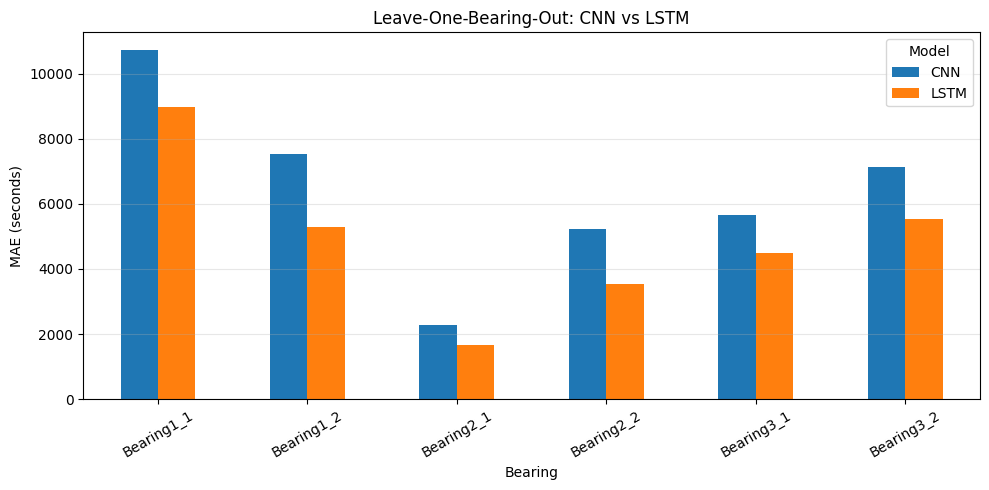

In [ ]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# 1. Configuration
# ============================================================

tf.keras.utils.set_random_seed(42)

WINDOW_SIZE = 30
RUL_SCALE = 30000.0  # Fixed scale, not calculated per bearing
EPOCHS = 8
BATCH_SIZE = 64

# Use only the 12 vibration features; elapsed time is excluded
feature_cols = [
    "ch1_rms", "ch1_std", "ch1_mean_abs",
    "ch1_peak", "ch1_ptp", "ch1_kurtosis",
    "ch2_rms", "ch2_std", "ch2_mean_abs",
    "ch2_peak", "ch2_ptp", "ch2_kurtosis"
]

all_data = (
    features_df
    .sort_values(["bearing", "recording_no"])
    .reset_index(drop=True)
)

all_bearings = sorted(all_data["bearing"].unique())

print("Bearings:", all_bearings)
print("Number of independent bearings:", len(all_bearings))
print("Features per recording:", len(feature_cols))
print("Sequence window:", WINDOW_SIZE)

# ============================================================
# 2. Build sequences without mixing bearings
# ============================================================

def make_windows(frame, scaled_features):
    X, y = [], []

    for _, group in frame.groupby("bearing", sort=False):
        # Frame has reset indices, aligned with scaled_features
        positions = group.index.to_numpy()
        bearing_X = scaled_features[positions]
        bearing_y = group["RUL_seconds"].to_numpy(dtype=np.float32)

        for end in range(WINDOW_SIZE - 1, len(group)):
            start = end - WINDOW_SIZE + 1

            X.append(bearing_X[start:end + 1])
            y.append(bearing_y[end])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.float32)
    )

# ============================================================
# 3. Define comparable models with linear output
# ============================================================

def build_model(model_type):
    inputs = keras.Input(
        shape=(WINDOW_SIZE, len(feature_cols))
    )

    if model_type == "CNN":
        x = layers.Conv1D(
            32, 5, padding="same", activation="relu"
        )(inputs)
        x = layers.MaxPooling1D(2)(x)
        x = layers.Conv1D(
            32, 3, padding="same", activation="relu"
        )(x)
        x = layers.GlobalAveragePooling1D()(x)

    elif model_type == "LSTM":
        x = layers.LSTM(32)(inputs)
        x = layers.Dropout(0.2)(x)

    else:
        raise ValueError(f"Unknown model type: {model_type}")

    x = layers.Dense(32, activation="relu")(x)

    # Linear output allows predictions outside [0, 1]
    outputs = layers.Dense(1)(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0003),
        loss="mse"
    )

    return model

# ============================================================
# 4. Leave-one-bearing-out cross-validation
# ============================================================

fold_results = []
oof_predictions = {"CNN": [], "LSTM": []}
oof_actual = []

for fold_no, held_out in enumerate(all_bearings, start=1):
    print(f"\n{'=' * 60}")
    print(f"Fold {fold_no}/{len(all_bearings)} — held-out: {held_out}")

    fold_train = (
        all_data[all_data["bearing"] != held_out]
        .sort_values(["bearing", "recording_no"])
        .reset_index(drop=True)
    )

    fold_test = (
        all_data[all_data["bearing"] == held_out]
        .sort_values(["bearing", "recording_no"])
        .reset_index(drop=True)
    )

    # Fit preprocessing on the five training bearings only
    fold_scaler = StandardScaler()

    X_fold_train = fold_scaler.fit_transform(
        fold_train[feature_cols]
    )
    X_fold_test = fold_scaler.transform(
        fold_test[feature_cols]
    )

    X_tr, y_tr = make_windows(fold_train, X_fold_train)
    X_te, y_te = make_windows(fold_test, X_fold_test)

    y_tr_scaled = y_tr / RUL_SCALE

    print("Training sequences:", X_tr.shape)
    print("Held-out sequences:", X_te.shape)

    oof_actual.append(y_te)

    for model_type in ["CNN", "LSTM"]:
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(100 + fold_no)

        model = build_model(model_type)

        model.fit(
            X_tr,
            y_tr_scaled,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            shuffle=True,
            verbose=0
        )

        pred = (
            model.predict(X_te, verbose=0).flatten()
            * RUL_SCALE
        )

        mae = mean_absolute_error(y_te, pred)
        rmse = np.sqrt(mean_squared_error(y_te, pred))
        r2 = r2_score(y_te, pred)

        fold_results.append({
            "Bearing": held_out,
            "Model": model_type,
            "Recordings": len(y_te),
            "MAE (seconds)": mae,
            "RMSE (seconds)": rmse,
            "R2": r2
        })

        oof_predictions[model_type].append(pred)

        print(
            f"{model_type}: MAE={mae:.1f}s, "
            f"RMSE={rmse:.1f}s, R2={r2:.3f}"
        )

        del model
        gc.collect()

# ============================================================
# 5. Report results for each held-out bearing
# ============================================================

fold_results_df = pd.DataFrame(fold_results)

print("\n=== PER-BEARING RESULTS ===")
display(
    fold_results_df
    .sort_values(["Bearing", "Model"])
    .round(3)
)

# ============================================================
# 6. Aggregate out-of-fold predictions
# ============================================================

actual_all = np.concatenate(oof_actual)

summary = []

for model_type in ["CNN", "LSTM"]:
    pred_all = np.concatenate(oof_predictions[model_type])

    summary.append({
        "Model": model_type,
        "MAE (seconds)": mean_absolute_error(actual_all, pred_all),
        "RMSE (seconds)": np.sqrt(
            mean_squared_error(actual_all, pred_all)
        ),
        "R2": r2_score(actual_all, pred_all)
    })

summary_df = pd.DataFrame(summary)

print("\n=== OVERALL OUT-OF-FOLD RESULTS ===")
display(summary_df.round(3))

# Plot the per-bearing MAE comparison
mae_pivot = fold_results_df.pivot(
    index="Bearing",
    columns="Model",
    values="MAE (seconds)"
)

mae_pivot.plot(kind="bar", figsize=(10, 5))
plt.ylabel("MAE (seconds)")
plt.title("Leave-One-Bearing-Out: CNN vs LSTM")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

=== FEATURE–RUL SPEARMAN CORRELATIONS ===
Negative correlation: feature tends to increase as RUL decreases.
Positive correlation: feature tends to decrease as RUL decreases.


,ch1_rms,ch2_rms,ch1_std,ch2_std,ch1_kurtosis,ch2_kurtosis,ch1_mean_abs,ch2_mean_abs
Bearing,,,,,,,,
Bearing1_1,-0.862,-0.440,-0.862,-0.440,-0.845,-0.531,-0.858,-0.424
Bearing1_2,-0.088,0.235,-0.091,0.236,-0.384,-0.071,0.058,0.431
Bearing2_1,-0.321,-0.515,-0.321,-0.515,-0.498,-0.480,-0.279,-0.461
Bearing2_2,-0.798,-0.532,-0.798,-0.532,-0.620,-0.580,-0.783,-0.524
Bearing3_1,0.423,0.007,0.432,0.005,-0.224,-0.397,0.485,0.066
Bearing3_2,0.144,0.061,0.145,0.061,-0.372,-0.113,0.228,0.083



=== MEAN ABSOLUTE CORRELATION ACROSS BEARINGS ===


,Mean absolute Spearman correlation
ch1_kurtosis,0.490
ch1_mean_abs,0.449
ch1_std,0.441
ch1_rms,0.439
ch2_kurtosis,0.362
ch2_mean_abs,0.331
ch2_rms,0.298
ch2_std,0.298


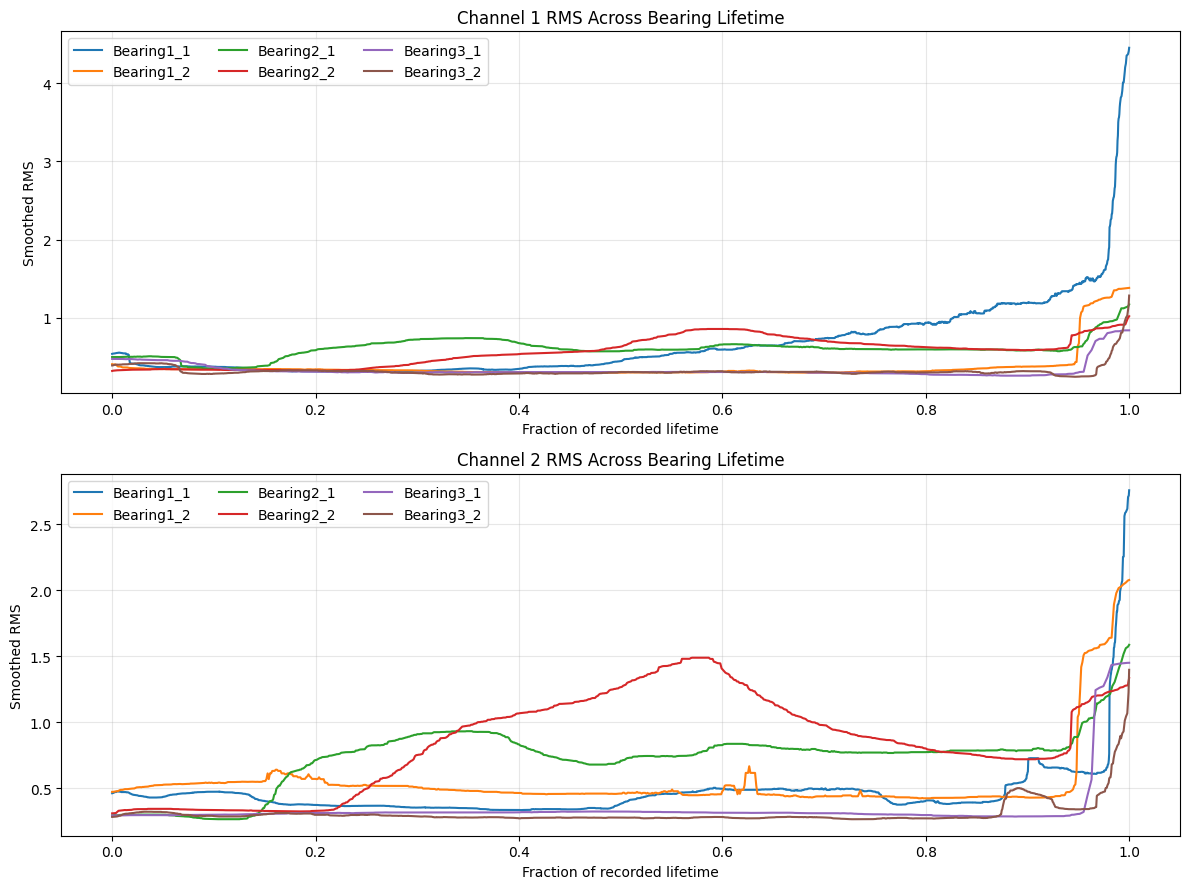

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

# ============================================================
# 1. Calculate correlations separately for each bearing
# ============================================================

diagnostic_features = [
    "ch1_rms", "ch2_rms",
    "ch1_std", "ch2_std",
    "ch1_kurtosis", "ch2_kurtosis",
    "ch1_mean_abs", "ch2_mean_abs"
]

correlation_rows = []

for bearing, group in features_df.groupby("bearing", sort=True):
    row = {"Bearing": bearing}

    for feature in diagnostic_features:
        corr, _ = spearmanr(
            group[feature],
            group["RUL_seconds"]
        )
        row[feature] = corr

    correlation_rows.append(row)

correlation_df = pd.DataFrame(correlation_rows).set_index("Bearing")

print("=== FEATURE–RUL SPEARMAN CORRELATIONS ===")
print("Negative correlation: feature tends to increase as RUL decreases.")
print("Positive correlation: feature tends to decrease as RUL decreases.")
display(correlation_df.round(3))

print("\n=== MEAN ABSOLUTE CORRELATION ACROSS BEARINGS ===")
importance_by_corr = (
    correlation_df.abs()
    .mean()
    .sort_values(ascending=False)
    .rename("Mean absolute Spearman correlation")
    .to_frame()
)

display(importance_by_corr.round(3))

# ============================================================
# 2. Plot smoothed RMS over normalized lifetime
# This is retrospective diagnosis, not a model input.
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 9))

for bearing, group in features_df.groupby("bearing", sort=True):
    group = group.sort_values("recording_no").copy()

    last_recording = group["recording_no"].max()

    if last_recording > 1:
        group["life_fraction"] = (
            (group["recording_no"] - 1) / (last_recording - 1)
        )
    else:
        group["life_fraction"] = 0.0

    # Smooth local fluctuations for visualization only
    for ax, feature in zip(axes, ["ch1_rms", "ch2_rms"]):
        smoothed = (
            group[feature]
            .rolling(window=51, center=True, min_periods=1)
            .median()
        )

        ax.plot(
            group["life_fraction"],
            smoothed,
            label=bearing,
            linewidth=1.5
        )

axes[0].set_title("Channel 1 RMS Across Bearing Lifetime")
axes[1].set_title("Channel 2 RMS Across Bearing Lifetime")

for ax in axes:
    ax.set_xlabel("Fraction of recorded lifetime")
    ax.set_ylabel("Smoothed RMS")
    ax.grid(True, alpha=0.3)
    ax.legend(ncol=3)

plt.tight_layout()
plt.show()

Baseline normalization complete.
Bearings: ['Bearing1_1', 'Bearing1_2', 'Bearing2_1', 'Bearing2_2', 'Bearing3_1', 'Bearing3_2']
Baseline recordings per bearing: 30

Fold 1/6: Bearing1_1
MAE=9383.3s | RMSE=10838.0s | R2=-0.832

Fold 2/6: Bearing1_2
MAE=8526.1s | RMSE=9182.5s | R2=-13.272

Fold 3/6: Bearing2_1
MAE=3511.5s | RMSE=4837.2s | R2=-2.609

Fold 4/6: Bearing2_2
MAE=4033.6s | RMSE=4894.7s | R2=-3.874

Fold 5/6: Bearing3_1
MAE=7431.7s | RMSE=7865.8s | R2=-30.434

Fold 6/6: Bearing3_2
MAE=3195.1s | RMSE=3790.8s | R2=0.333

=== BASELINE-RELATIVE LSTM: PER-BEARING RESULTS ===


,Bearing,MAE (seconds),RMSE (seconds),R2
0,Bearing1_1,9383.277,10838.047,-0.832
1,Bearing1_2,8526.089,9182.515,-13.272
2,Bearing2_1,3511.526,4837.196,-2.609
3,Bearing2_2,4033.647,4894.659,-3.874
4,Bearing3_1,7431.664,7865.792,-30.434
5,Bearing3_2,3195.129,3790.775,0.333



=== OVERALL OUT-OF-FOLD RESULTS ===
MAE:  6542.49 seconds (109.04 minutes)
RMSE: 8151.52 seconds (135.86 minutes)
R2:   -0.3108

=== EXPERIMENT COMPARISON ===


,Experiment,MAE,RMSE,R2
0,Original features,6069.478,8151.625,-0.311
1,Baseline-relative features,6542.491,8151.523,-0.311


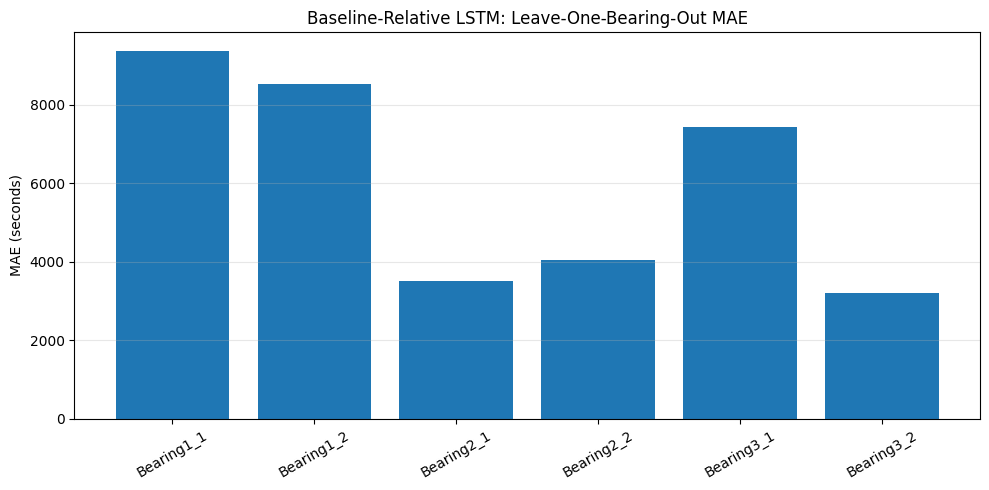

In [ ]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# ============================================================
# 1. Configuration
# ============================================================

WINDOW_SIZE = 30
BASELINE_WINDOW = 30
RUL_SCALE = 30000.0
EPOCHS = 8
BATCH_SIZE = 64

feature_cols = [
    "ch1_rms", "ch1_std", "ch1_mean_abs",
    "ch1_peak", "ch1_ptp", "ch1_kurtosis",
    "ch2_rms", "ch2_std", "ch2_mean_abs",
    "ch2_peak", "ch2_ptp", "ch2_kurtosis"
]

all_data = (
    features_df
    .sort_values(["bearing", "recording_no"])
    .reset_index(drop=True)
)

all_bearings = sorted(all_data["bearing"].unique())

# ============================================================
# 2. Normalize each bearing relative to its initial condition
# ============================================================

relative_df = all_data.copy()

for bearing, group in all_data.groupby("bearing", sort=True):
    group = group.sort_values("recording_no")
    idx = group.index

    # Use only the initial 30 recordings to estimate baseline
    initial = group.iloc[:BASELINE_WINDOW][feature_cols]

    baseline_median = initial.median()
    baseline_mad = (
        initial.sub(baseline_median)
        .abs()
        .median() * 1.4826
    )

    # Prevent division by very small baseline variation
    scale_floor = np.maximum(
        0.1 * baseline_median.abs().to_numpy(),
        0.01
    )

    baseline_scale = np.maximum(
        baseline_mad.to_numpy(),
        scale_floor
    )

    # Convert absolute features into deviations from baseline
    relative_df.loc[idx, feature_cols] = (
        group[feature_cols].to_numpy()
        - baseline_median.to_numpy()
    ) / baseline_scale

print("Baseline normalization complete.")
print("Bearings:", all_bearings)
print("Baseline recordings per bearing:", BASELINE_WINDOW)

# ============================================================
# 3. Create sequences independently for each bearing
# ============================================================

def create_windows(frame, scaled_features):
    X, y = [], []

    for _, group in frame.groupby("bearing", sort=False):
        positions = group.index.to_numpy()
        bearing_X = scaled_features[positions]
        bearing_y = group["RUL_seconds"].to_numpy(dtype=np.float32)

        for end in range(WINDOW_SIZE - 1, len(group)):
            start = end - WINDOW_SIZE + 1

            X.append(bearing_X[start:end + 1])
            y.append(bearing_y[end])

    return np.asarray(X, dtype=np.float32), np.asarray(y, dtype=np.float32)


def build_lstm_model():
    model = keras.Sequential([
        layers.Input(shape=(WINDOW_SIZE, len(feature_cols))),
        layers.LSTM(32),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1)
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0003),
        loss="mse"
    )

    return model

# ============================================================
# 4. Leave-one-bearing-out validation
# ============================================================

relative_results = []
relative_predictions = {}
relative_actual = {}

for fold_no, held_out in enumerate(all_bearings, start=1):
    print(f"\nFold {fold_no}/{len(all_bearings)}: {held_out}")

    fold_train = (
        relative_df[relative_df["bearing"] != held_out]
        .sort_values(["bearing", "recording_no"])
        .reset_index(drop=True)
    )

    fold_test = (
        relative_df[relative_df["bearing"] == held_out]
        .sort_values(["bearing", "recording_no"])
        .reset_index(drop=True)
    )

    # Fit global feature scaling on training bearings only
    scaler = StandardScaler()

    X_train_fold = scaler.fit_transform(
        fold_train[feature_cols]
    )
    X_test_fold = scaler.transform(
        fold_test[feature_cols]
    )

    X_train_fold_seq, y_train_fold = create_windows(
        fold_train, X_train_fold
    )
    X_test_fold_seq, y_test_fold = create_windows(
        fold_test, X_test_fold
    )

    y_train_fold_scaled = y_train_fold / RUL_SCALE

    keras.backend.clear_session()
    tf.keras.utils.set_random_seed(100 + fold_no)

    model = build_lstm_model()

    model.fit(
        X_train_fold_seq,
        y_train_fold_scaled,
        epochs=EPOCHS,
        batch_size=BATCH_SIZE,
        shuffle=True,
        verbose=0
    )

    predictions = (
        model.predict(X_test_fold_seq, verbose=0).flatten()
        * RUL_SCALE
    )

    mae = mean_absolute_error(y_test_fold, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_fold, predictions))
    r2 = r2_score(y_test_fold, predictions)

    relative_results.append({
        "Bearing": held_out,
        "MAE (seconds)": mae,
        "RMSE (seconds)": rmse,
        "R2": r2
    })

    relative_predictions[held_out] = predictions
    relative_actual[held_out] = y_test_fold

    print(
        f"MAE={mae:.1f}s | RMSE={rmse:.1f}s | R2={r2:.3f}"
    )

    del model
    gc.collect()

# ============================================================
# 5. Summarize performance across all held-out bearings
# ============================================================

relative_results_df = pd.DataFrame(relative_results)

print("\n=== BASELINE-RELATIVE LSTM: PER-BEARING RESULTS ===")
display(relative_results_df.round(3))

all_actual = np.concatenate([
    relative_actual[b] for b in all_bearings
])

all_predictions = np.concatenate([
    relative_predictions[b] for b in all_bearings
])

overall_mae = mean_absolute_error(all_actual, all_predictions)
overall_rmse = np.sqrt(mean_squared_error(all_actual, all_predictions))
overall_r2 = r2_score(all_actual, all_predictions)

print("\n=== OVERALL OUT-OF-FOLD RESULTS ===")
print(f"MAE:  {overall_mae:.2f} seconds ({overall_mae / 60:.2f} minutes)")
print(f"RMSE: {overall_rmse:.2f} seconds ({overall_rmse / 60:.2f} minutes)")
print(f"R2:   {overall_r2:.4f}")

# Compare with previous unnormalized-feature LSTM results
previous_lstm_mae = 6069.478
previous_lstm_rmse = 8151.625
previous_lstm_r2 = -0.311

comparison = pd.DataFrame([
    {
        "Experiment": "Original features",
        "MAE": previous_lstm_mae,
        "RMSE": previous_lstm_rmse,
        "R2": previous_lstm_r2
    },
    {
        "Experiment": "Baseline-relative features",
        "MAE": overall_mae,
        "RMSE": overall_rmse,
        "R2": overall_r2
    }
])

print("\n=== EXPERIMENT COMPARISON ===")
display(comparison.round(3))

# Plot MAE by held-out bearing
plt.figure(figsize=(10, 5))
plt.bar(
    relative_results_df["Bearing"],
    relative_results_df["MAE (seconds)"]
)
plt.ylabel("MAE (seconds)")
plt.title("Baseline-Relative LSTM: Leave-One-Bearing-Out MAE")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

RUL cap: 4000.0 seconds
Training bearings available: 6
Input features: 12
Window size: 30

Fold 1/6: Bearing1_1
Training sequences: (4586, 30, 12)
Held-out sequences: (2774, 30, 12)
CNN: capped MAE=393.0s, capped RMSE=788.0s, late-life MAE=1598.6s
LSTM: capped MAE=588.2s, capped RMSE=972.8s, late-life MAE=723.4s

Fold 2/6: Bearing1_2
Training sequences: (6518, 30, 12)
Held-out sequences: (842, 30, 12)
CNN: capped MAE=752.3s, capped RMSE=1270.0s, late-life MAE=1490.9s
LSTM: capped MAE=725.7s, capped RMSE=1051.2s, late-life MAE=1220.7s

Fold 3/6: Bearing2_1
Training sequences: (6478, 30, 12)
Held-out sequences: (882, 30, 12)
CNN: capped MAE=1101.6s, capped RMSE=1376.0s, late-life MAE=916.9s
LSTM: capped MAE=789.7s, capped RMSE=1050.2s, late-life MAE=1054.4s

Fold 4/6: Bearing2_2
Training sequences: (6592, 30, 12)
Held-out sequences: (768, 30, 12)
CNN: capped MAE=1000.3s, capped RMSE=1302.8s, late-life MAE=1495.6s
LSTM: capped MAE=1159.5s, capped RMSE=1521.5s, late-life MAE=1407.2s

Fold 

,Bearing,Model,Capped MAE (sec),Capped RMSE (sec),Late-life MAE (sec),Late-life recordings
0,Bearing1_1,CNN,392.96,787.98,1598.55,401
1,Bearing1_1,LSTM,588.23,972.83,723.35,401
2,Bearing1_2,CNN,752.35,1269.99,1490.91,401
3,Bearing1_2,LSTM,725.68,1051.22,1220.66,401
4,Bearing2_1,CNN,1101.62,1375.98,916.94,401
5,Bearing2_1,LSTM,789.70,1050.18,1054.43,401
6,Bearing2_2,CNN,1000.32,1302.80,1495.62,401
7,Bearing2_2,LSTM,1159.54,1521.52,1407.24,401
8,Bearing3_1,CNN,1147.02,1549.80,1371.37,401
9,Bearing3_1,LSTM,1251.13,1569.61,1511.66,401



=== OVERALL OUT-OF-FOLD RESULTS ===


,Model,Capped MAE (sec),Capped RMSE (sec),Capped R2,Late-life MAE (sec)
0,CNN,881.727,1261.553,-0.207,1320.660
1,LSTM,916.454,1259.728,-0.204,1171.183


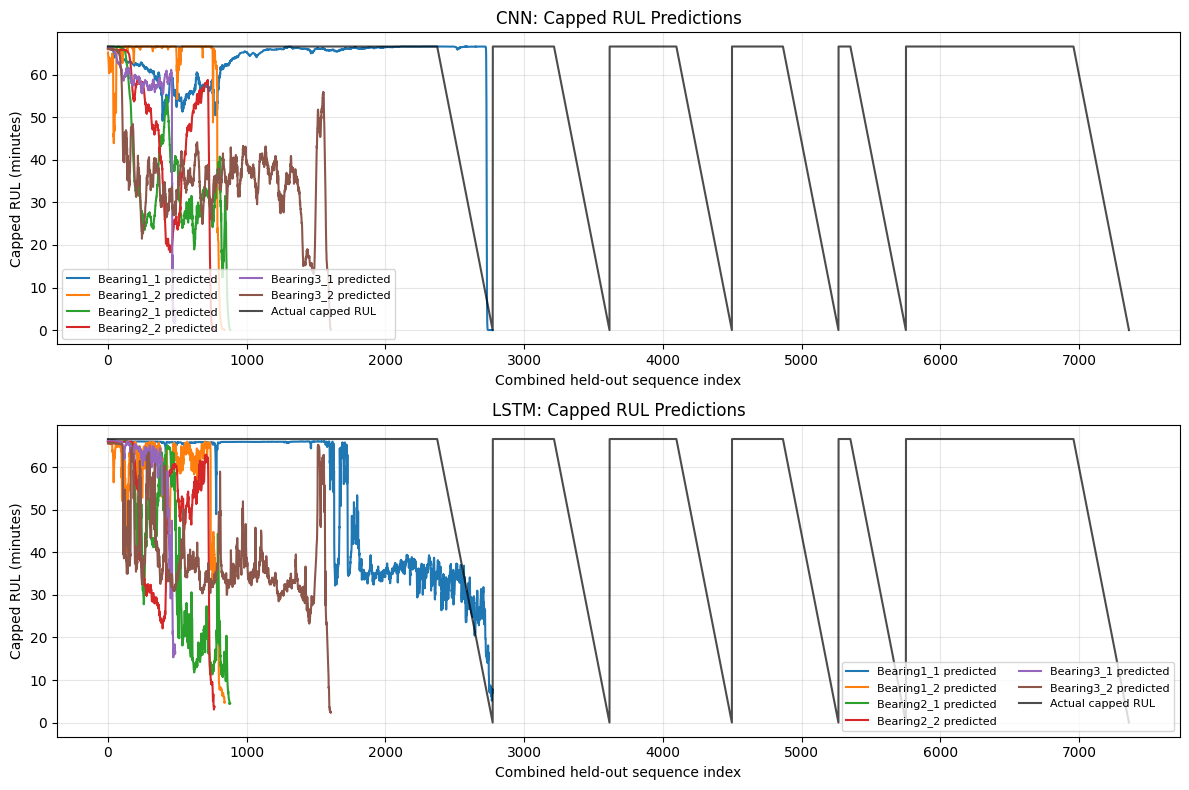

In [ ]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# 1. Configuration
# ============================================================

WINDOW_SIZE = 30
RUL_CAP = 4000.0
EPOCHS = 8
BATCH_SIZE = 64

tf.keras.utils.set_random_seed(42)

feature_cols = [
    "ch1_rms", "ch1_std", "ch1_mean_abs",
    "ch1_peak", "ch1_ptp", "ch1_kurtosis",
    "ch2_rms", "ch2_std", "ch2_mean_abs",
    "ch2_peak", "ch2_ptp", "ch2_kurtosis"
]

all_data = (
    features_df
    .sort_values(["bearing", "recording_no"])
    .reset_index(drop=True)
)

all_bearings = sorted(all_data["bearing"].unique())

print("RUL cap:", RUL_CAP, "seconds")
print("Training bearings available:", len(all_bearings))
print("Input features:", len(feature_cols))
print("Window size:", WINDOW_SIZE)

# ============================================================
# 2. Create sequences with capped RUL labels
# ============================================================

def make_capped_windows(frame, scaled_features):
    X, y_capped, y_original = [], [], []

    for _, group in frame.groupby("bearing", sort=False):
        positions = group.index.to_numpy()
        bearing_X = scaled_features[positions]

        bearing_rul = group["RUL_seconds"].to_numpy(
            dtype=np.float32
        )
        bearing_capped_rul = np.minimum(
            bearing_rul, RUL_CAP
        )

        for end in range(WINDOW_SIZE - 1, len(group)):
            start = end - WINDOW_SIZE + 1

            X.append(bearing_X[start:end + 1])
            y_capped.append(bearing_capped_rul[end])
            y_original.append(bearing_rul[end])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y_capped, dtype=np.float32),
        np.asarray(y_original, dtype=np.float32)
    )

# ============================================================
# 3. Define CNN and LSTM models
# ============================================================

def build_model(model_type):
    inputs = keras.Input(
        shape=(WINDOW_SIZE, len(feature_cols))
    )

    if model_type == "CNN":
        x = layers.Conv1D(
            32, 5, padding="same", activation="relu"
        )(inputs)
        x = layers.MaxPooling1D(2)(x)
        x = layers.Conv1D(
            32, 3, padding="same", activation="relu"
        )(x)
        x = layers.GlobalAveragePooling1D()(x)

    elif model_type == "LSTM":
        x = layers.LSTM(32)(inputs)
        x = layers.Dropout(0.2)(x)

    else:
        raise ValueError("Unknown model type: " + model_type)

    x = layers.Dense(32, activation="relu")(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0003),
        loss="mse"
    )
    return model

# ============================================================
# 4. Leave-one-bearing-out evaluation
# ============================================================

fold_results = []
all_actual_capped = []
all_actual_original = []
all_predictions = {"CNN": [], "LSTM": []}

for fold_no, held_out in enumerate(all_bearings, start=1):
    print(f"\nFold {fold_no}/{len(all_bearings)}: {held_out}")

    fold_train = (
        all_data[all_data["bearing"] != held_out]
        .sort_values(["bearing", "recording_no"])
        .reset_index(drop=True)
    )

    fold_test = (
        all_data[all_data["bearing"] == held_out]
        .sort_values(["bearing", "recording_no"])
        .reset_index(drop=True)
    )

    # Fit feature scaling using only training bearings
    scaler = StandardScaler()

    X_train_raw = scaler.fit_transform(
        fold_train[feature_cols]
    )
    X_test_raw = scaler.transform(
        fold_test[feature_cols]
    )

    X_tr, y_tr_cap, _ = make_capped_windows(
        fold_train, X_train_raw
    )

    X_te, y_te_cap, y_te_original = make_capped_windows(
        fold_test, X_test_raw
    )

    # Network target range is 0 to 1
    y_tr = y_tr_cap / RUL_CAP

    all_actual_capped.append(y_te_cap)
    all_actual_original.append(y_te_original)

    print("Training sequences:", X_tr.shape)
    print("Held-out sequences:", X_te.shape)

    for model_type in ["CNN", "LSTM"]:
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(100 + fold_no)

        model = build_model(model_type)

        model.fit(
            X_tr,
            y_tr,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            shuffle=True,
            verbose=0
        )

        pred_scaled = model.predict(
            X_te, verbose=0
        ).flatten()

        pred_capped = np.clip(
            pred_scaled * RUL_CAP, 0, RUL_CAP
        )

        # Main metric: prediction of the capped RUL target
        capped_mae = mean_absolute_error(
            y_te_cap, pred_capped
        )
        capped_rmse = np.sqrt(
            mean_squared_error(y_te_cap, pred_capped)
        )

        # Secondary metric: performance during the final RUL_CAP seconds
        late_mask = y_te_original <= RUL_CAP

        late_mae = (
            mean_absolute_error(
                y_te_original[late_mask],
                pred_capped[late_mask]
            )
            if late_mask.any()
            else np.nan
        )

        fold_results.append({
            "Bearing": held_out,
            "Model": model_type,
            "Capped MAE (sec)": capped_mae,
            "Capped RMSE (sec)": capped_rmse,
            "Late-life MAE (sec)": late_mae,
            "Late-life recordings": int(late_mask.sum())
        })

        all_predictions[model_type].append(pred_capped)

        print(
            f"{model_type}: capped MAE={capped_mae:.1f}s, "
            f"capped RMSE={capped_rmse:.1f}s, "
            f"late-life MAE={late_mae:.1f}s"
        )

        del model
        gc.collect()

# ============================================================
# 5. Aggregate metrics across all six held-out bearings
# ============================================================

actual_capped_all = np.concatenate(all_actual_capped)
actual_original_all = np.concatenate(all_actual_original)

fold_results_df = pd.DataFrame(fold_results)

summary_rows = []

for model_type in ["CNN", "LSTM"]:
    predicted_all = np.concatenate(
        all_predictions[model_type]
    )

    late_mask_all = actual_original_all <= RUL_CAP

    summary_rows.append({
        "Model": model_type,
        "Capped MAE (sec)": mean_absolute_error(
            actual_capped_all, predicted_all
        ),
        "Capped RMSE (sec)": np.sqrt(
            mean_squared_error(
                actual_capped_all, predicted_all
            )
        ),
        "Capped R2": r2_score(
            actual_capped_all, predicted_all
        ),
        "Late-life MAE (sec)": mean_absolute_error(
            actual_original_all[late_mask_all],
            predicted_all[late_mask_all]
        )
    })

summary_df = pd.DataFrame(summary_rows)

print("\n=== PER-BEARING RESULTS ===")
display(fold_results_df.round(2))

print("\n=== OVERALL OUT-OF-FOLD RESULTS ===")
display(summary_df.round(3))

# ============================================================
# 6. Plot capped actual versus predicted RUL
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(12, 8))

offset = 0

for bearing in all_bearings:
    group = all_data[all_data["bearing"] == bearing]
    n = max(len(group) - WINDOW_SIZE + 1, 0)

    if n == 0:
        continue

    actual = actual_capped_all[offset:offset + n]

    for ax, model_type in zip(axes, ["CNN", "LSTM"]):
        predicted = np.concatenate(
            all_predictions[model_type]
        )[offset:offset + n]

        ax.plot(
            np.arange(n),
            predicted / 60,
            label=f"{bearing} predicted"
        )

    offset += n

# Separate plot showing all predictions against actual capped labels
axes[0].plot(
    actual_capped_all / 60,
    color="black",
    alpha=0.7,
    label="Actual capped RUL"
)
axes[0].set_title("CNN: Capped RUL Predictions")
axes[1].plot(
    actual_capped_all / 60,
    color="black",
    alpha=0.7,
    label="Actual capped RUL"
)
axes[1].set_title("LSTM: Capped RUL Predictions")

for ax in axes:
    ax.set_xlabel("Combined held-out sequence index")
    ax.set_ylabel("Capped RUL (minutes)")
    ax.legend(ncol=2, fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

=== OVERALL CAPPED-RUL COMPARISON ===


,Model,Capped MAE (sec),Capped RMSE (sec),Capped R2
0,Constant 4000-sec baseline,653.804,1321.233,-0.324
1,CNN,881.727,1261.553,-0.207
2,LSTM,916.454,1259.728,-0.204



=== FINAL 4000 SECONDS OF BEARING LIFE ===


,Model,Late-life MAE (sec),Late-life RMSE (sec)
0,Constant 4000-sec baseline,2000.000,2310.844
1,CNN,1320.660,1615.238
2,LSTM,1171.183,1441.239


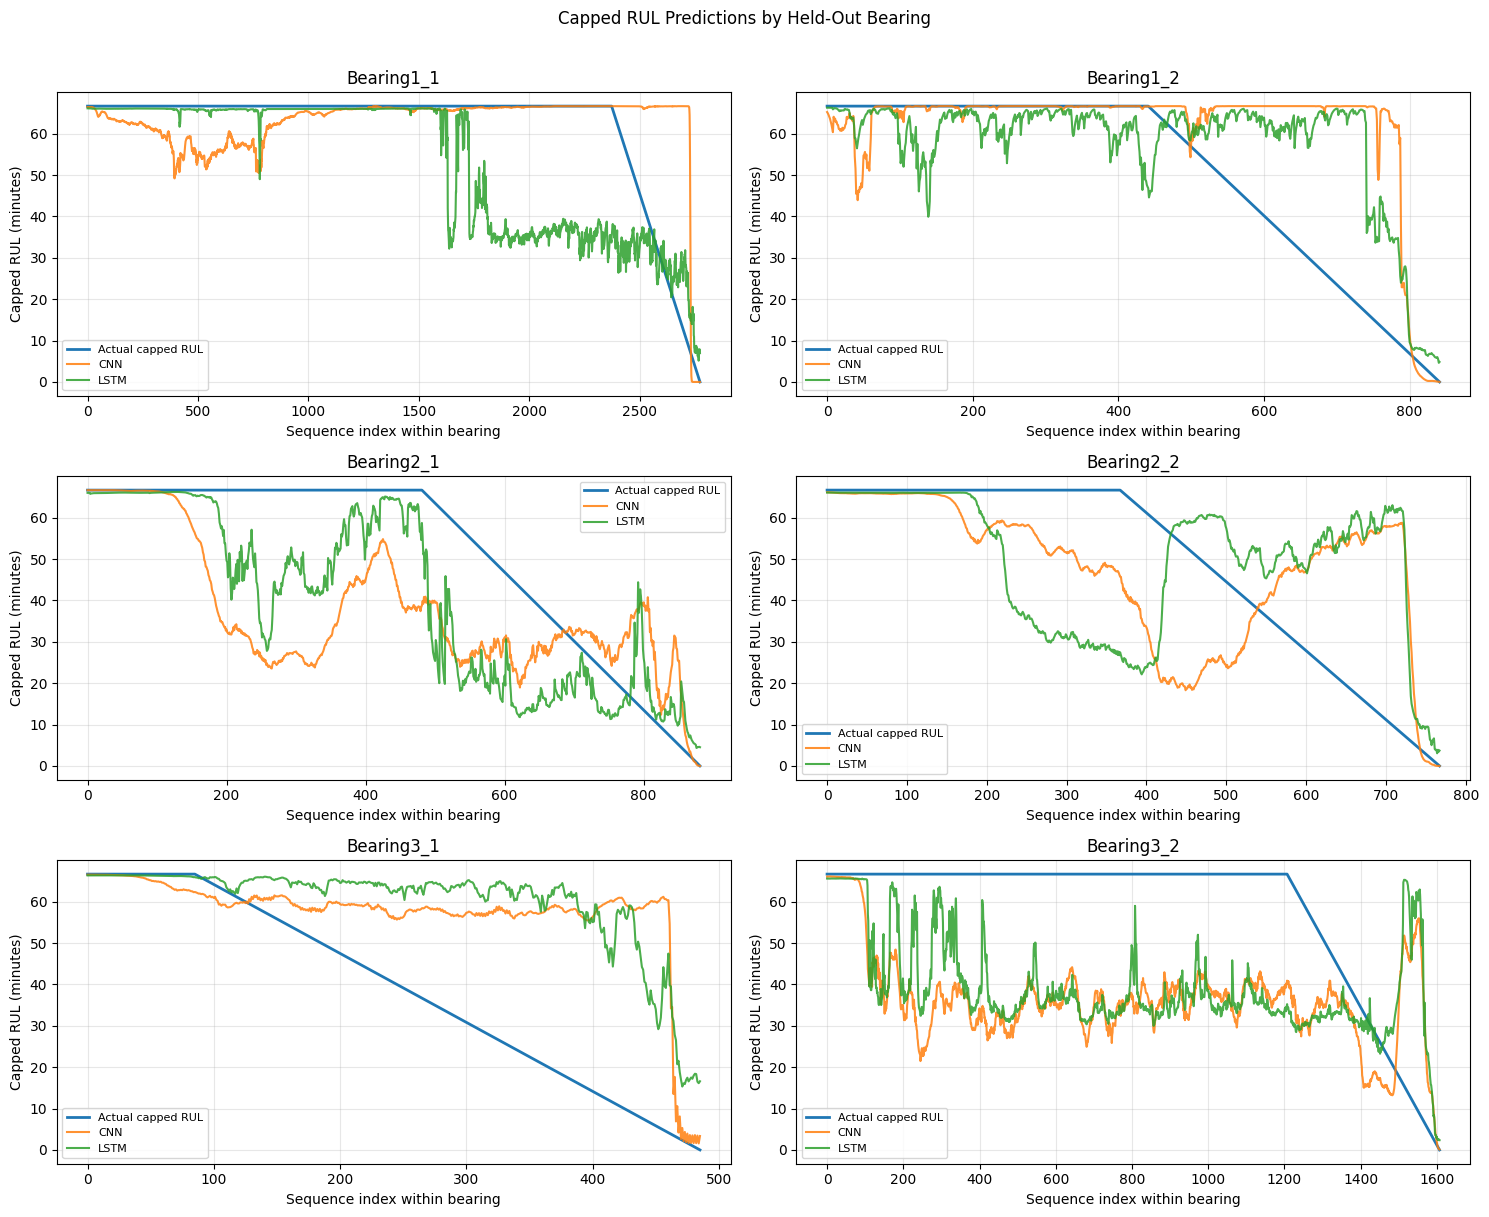

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# 1. Evaluate the constant 4000-second baseline
# ============================================================

baseline_predictions = []
actual_capped_all = np.concatenate(all_actual_capped)

for y_true in all_actual_capped:
    # Predict the cap for every recording
    baseline_predictions.append(
        np.full(len(y_true), RUL_CAP, dtype=np.float32)
    )

baseline_all = np.concatenate(baseline_predictions)

model_predictions = {
    "Constant 4000-sec baseline": baseline_all,
    "CNN": np.concatenate(all_predictions["CNN"]),
    "LSTM": np.concatenate(all_predictions["LSTM"])
}

comparison_rows = []

for model_name, pred in model_predictions.items():
    comparison_rows.append({
        "Model": model_name,
        "Capped MAE (sec)": mean_absolute_error(
            actual_capped_all, pred
        ),
        "Capped RMSE (sec)": np.sqrt(
            mean_squared_error(actual_capped_all, pred)
        ),
        "Capped R2": r2_score(actual_capped_all, pred)
    })

comparison_df = pd.DataFrame(comparison_rows)

print("=== OVERALL CAPPED-RUL COMPARISON ===")
display(comparison_df.round(3))

# ============================================================
# 2. Compare late-life performance
# ============================================================

actual_original_all = np.concatenate(all_actual_original)
late_mask = actual_original_all <= RUL_CAP

late_rows = []

for model_name, pred in model_predictions.items():
    late_rows.append({
        "Model": model_name,
        "Late-life MAE (sec)": mean_absolute_error(
            actual_original_all[late_mask],
            pred[late_mask]
        ),
        "Late-life RMSE (sec)": np.sqrt(
            mean_squared_error(
                actual_original_all[late_mask],
                pred[late_mask]
            )
        )
    })

late_df = pd.DataFrame(late_rows)

print("\n=== FINAL 4000 SECONDS OF BEARING LIFE ===")
display(late_df.round(3))

# ============================================================
# 3. Correct plots: one subplot per bearing
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for i, bearing in enumerate(all_bearings):
    ax = axes[i]

    # The lists are stored in the same order as all_bearings
    actual = all_actual_capped[i] / 60
    cnn_pred = all_predictions["CNN"][i] / 60
    lstm_pred = all_predictions["LSTM"][i] / 60

    ax.plot(actual, label="Actual capped RUL", linewidth=2)
    ax.plot(cnn_pred, label="CNN", alpha=0.85)
    ax.plot(lstm_pred, label="LSTM", alpha=0.85)

    ax.set_title(bearing)
    ax.set_xlabel("Sequence index within bearing")
    ax.set_ylabel("Capped RUL (minutes)")
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8)

plt.suptitle("Capped RUL Predictions by Held-Out Bearing", y=1.01)
plt.tight_layout()
plt.show()


Fold 1/6 — held out: Bearing1_1
Training sequences: (4586, 30, 12)
Target-group counts: [ 250  250  500  500  500 2586]
CNN: capped MAE=521.1s, late-life MAE=1357.0s
LSTM: capped MAE=1171.6s, late-life MAE=1408.8s

Fold 2/6 — held out: Bearing1_2
Training sequences: (6518, 30, 12)
Target-group counts: [ 250  250  500  500  500 4518]
CNN: capped MAE=812.9s, late-life MAE=1474.6s
LSTM: capped MAE=957.5s, late-life MAE=855.4s

Fold 3/6 — held out: Bearing2_1
Training sequences: (6478, 30, 12)
Target-group counts: [ 250  250  500  500  500 4478]
CNN: capped MAE=1275.7s, late-life MAE=1008.5s
LSTM: capped MAE=966.9s, late-life MAE=1225.9s

Fold 4/6 — held out: Bearing2_2
Training sequences: (6592, 30, 12)
Target-group counts: [ 250  250  500  500  500 4592]
CNN: capped MAE=1429.2s, late-life MAE=1569.8s
LSTM: capped MAE=1610.8s, late-life MAE=1539.2s

Fold 5/6 — held out: Bearing3_1
Training sequences: (6874, 30, 12)
Target-group counts: [ 250  250  500  500  500 4874]
CNN: capped MAE=693.

,Bearing,Model,Capped MAE (sec),Capped RMSE (sec),Late-life MAE (sec)
0,Bearing1_1,CNN,521.10,847.21,1357.00
1,Bearing1_1,LSTM,1171.64,1738.54,1408.83
2,Bearing1_2,CNN,812.90,1300.03,1474.56
3,Bearing1_2,LSTM,957.54,1086.56,855.40
4,Bearing2_1,CNN,1275.65,1565.14,1008.49
5,Bearing2_1,LSTM,966.86,1193.77,1225.85
6,Bearing2_2,CNN,1429.21,1751.70,1569.82
7,Bearing2_2,LSTM,1610.75,2063.44,1539.22
8,Bearing3_1,CNN,693.95,898.58,797.75
9,Bearing3_1,LSTM,719.47,921.02,816.85



=== OVERALL COMPARISON ===


,Model,Capped MAE (sec),Capped RMSE (sec),Late-life MAE (sec)
0,Constant baseline,653.80,1321.23,2000.00
1,CNN (unweighted),881.73,1261.55,1320.66
2,LSTM (unweighted),916.45,1259.73,1171.18
3,CNN (weighted),992.68,1345.09,1211.86
4,LSTM (weighted),1166.11,1584.19,1136.02


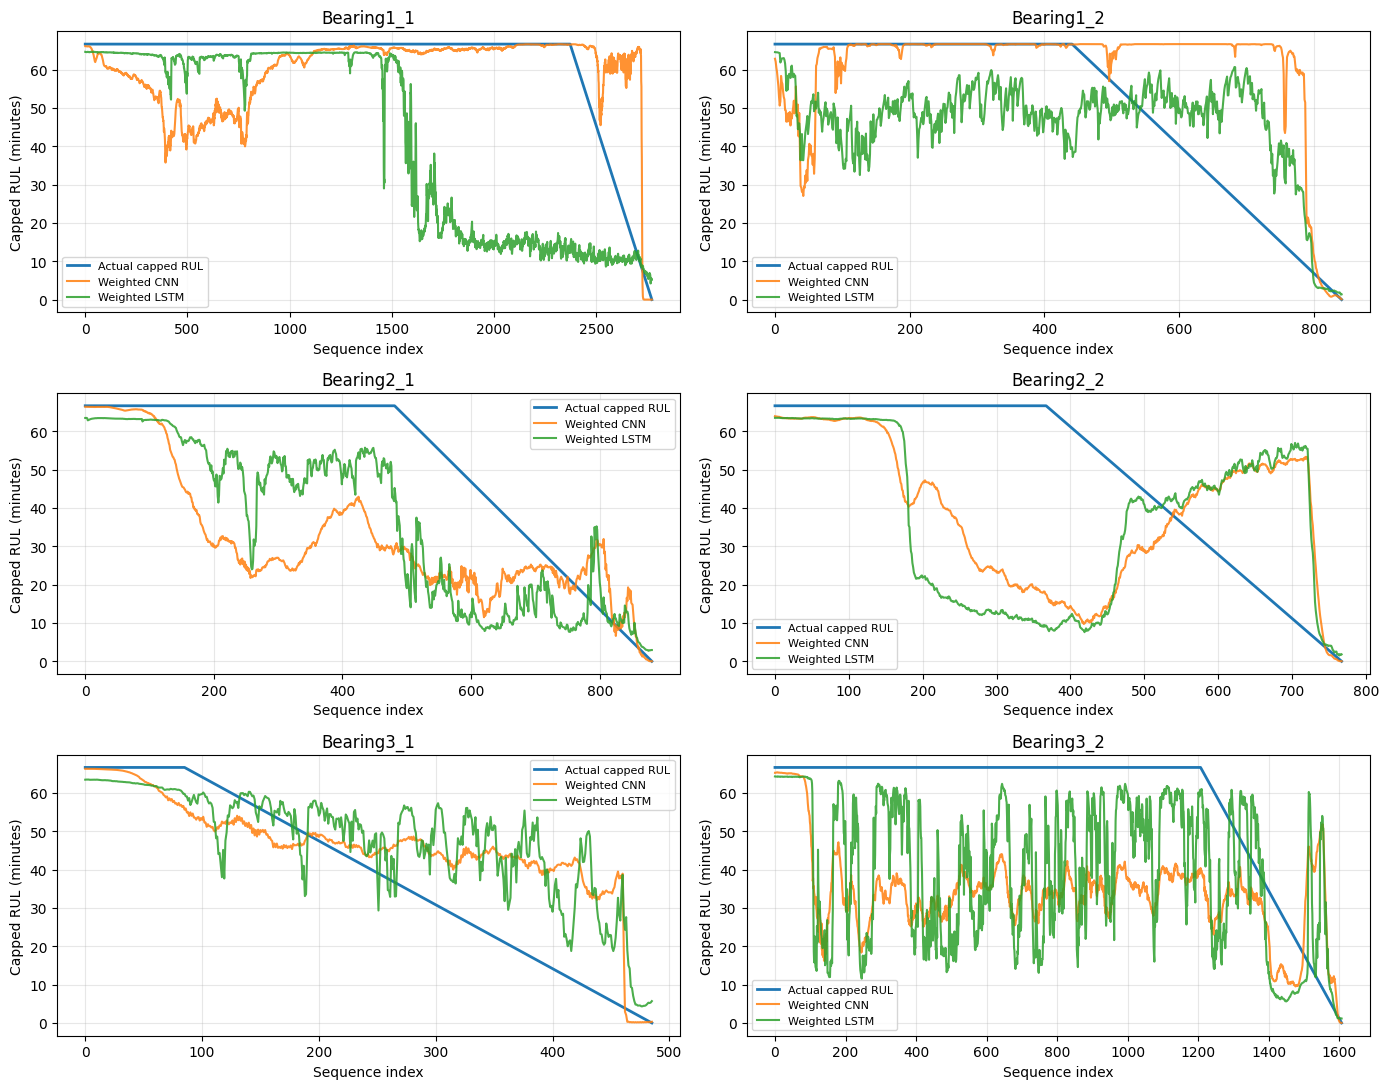

In [ ]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

tf.keras.utils.set_random_seed(42)

# ============================================================
# 1. Configuration
# ============================================================

WINDOW_SIZE = 30
RUL_CAP = 4000.0
EPOCHS = 8
BATCH_SIZE = 64

feature_cols = [
    "ch1_rms", "ch1_std", "ch1_mean_abs",
    "ch1_peak", "ch1_ptp", "ch1_kurtosis",
    "ch2_rms", "ch2_std", "ch2_mean_abs",
    "ch2_peak", "ch2_ptp", "ch2_kurtosis"
]

all_data = (
    features_df
    .sort_values(["bearing", "recording_no"])
    .reset_index(drop=True)
)
all_bearings = sorted(all_data["bearing"].unique())

# ============================================================
# 2. Sequence creation and target balancing
# ============================================================

def make_capped_windows(frame, scaled_features):
    X, y_cap, y_original = [], [], []

    for _, group in frame.groupby("bearing", sort=False):
        positions = group.index.to_numpy()
        bx = scaled_features[positions]
        by = group["RUL_seconds"].to_numpy(dtype=np.float32)

        for end in range(WINDOW_SIZE - 1, len(group)):
            start = end - WINDOW_SIZE + 1
            X.append(bx[start:end + 1])
            y_original.append(by[end])
            y_cap.append(min(by[end], RUL_CAP))

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y_cap, dtype=np.float32),
        np.asarray(y_original, dtype=np.float32)
    )


def calculate_sample_weights(y):
    """
    Balance six RUL groups:
    <500, 500-1000, 1000-2000, 2000-3000,
    3000-4000, and the capped-at-4000 group.
    """
    group_id = np.full(len(y), 5, dtype=int)

    group_id[(y < 4000) & (y >= 3000)] = 4
    group_id[(y < 3000) & (y >= 2000)] = 3
    group_id[(y < 2000) & (y >= 1000)] = 2
    group_id[(y < 1000) & (y >= 500)] = 1
    group_id[y < 500] = 0

    counts = np.bincount(group_id, minlength=6)
    active_groups = np.sum(counts > 0)

    weights = np.array([
        len(y) / (active_groups * counts[group])
        for group in group_id
    ], dtype=np.float32)

    # Normalize so the average sample weight is one
    weights /= weights.mean()
    return weights, counts


# ============================================================
# 3. Models
# ============================================================

def build_model(model_type):
    inp = keras.Input(shape=(WINDOW_SIZE, len(feature_cols)))

    if model_type == "CNN":
        x = layers.Conv1D(
            32, 5, padding="same", activation="relu"
        )(inp)
        x = layers.MaxPooling1D(2)(x)
        x = layers.Conv1D(
            32, 3, padding="same", activation="relu"
        )(x)
        x = layers.GlobalAveragePooling1D()(x)

    else:
        x = layers.LSTM(32)(inp)
        x = layers.Dropout(0.2)(x)

    x = layers.Dense(32, activation="relu")(x)
    out = layers.Dense(1, activation="sigmoid")(x)

    model = keras.Model(inp, out)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0003),
        loss="mse"
    )
    return model


# ============================================================
# 4. Six-fold leave-one-bearing-out evaluation
# ============================================================

weighted_results = []
weighted_predictions = {"CNN": [], "LSTM": []}
weighted_actual_capped = []
weighted_actual_original = []

for fold_no, held_out in enumerate(all_bearings, start=1):
    print(f"\nFold {fold_no}/6 — held out: {held_out}")

    fold_train = (
        all_data[all_data["bearing"] != held_out]
        .reset_index(drop=True)
    )
    fold_test = (
        all_data[all_data["bearing"] == held_out]
        .reset_index(drop=True)
    )

    scaler = StandardScaler()
    Xtr_raw = scaler.fit_transform(fold_train[feature_cols])
    Xte_raw = scaler.transform(fold_test[feature_cols])

    Xtr, ytr_cap, _ = make_capped_windows(fold_train, Xtr_raw)
    Xte, yte_cap, yte_original = make_capped_windows(fold_test, Xte_raw)

    # All outputs lie between 0 and 1
    ytr_scaled = ytr_cap / RUL_CAP

    # Weight rare lower-RUL regions more strongly
    sample_weights, bin_counts = calculate_sample_weights(ytr_cap)

    print("Training sequences:", Xtr.shape)
    print("Target-group counts:", bin_counts)

    weighted_actual_capped.append(yte_cap)
    weighted_actual_original.append(yte_original)

    for model_type in ["CNN", "LSTM"]:
        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(100 + fold_no)

        model = build_model(model_type)
        model.fit(
            Xtr,
            ytr_scaled,
            sample_weight=sample_weights,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            shuffle=True,
            verbose=0
        )

        pred = (
            model.predict(Xte, verbose=0).flatten()
            * RUL_CAP
        )
        pred = np.clip(pred, 0, RUL_CAP)

        late_mask = yte_original <= RUL_CAP

        weighted_results.append({
            "Bearing": held_out,
            "Model": model_type,
            "Capped MAE (sec)": mean_absolute_error(yte_cap, pred),
            "Capped RMSE (sec)": np.sqrt(
                mean_squared_error(yte_cap, pred)
            ),
            "Late-life MAE (sec)": mean_absolute_error(
                yte_original[late_mask], pred[late_mask]
            )
        })

        weighted_predictions[model_type].append(pred)

        print(
            f"{model_type}: "
            f"capped MAE={mean_absolute_error(yte_cap, pred):.1f}s, "
            f"late-life MAE="
            f"{mean_absolute_error(yte_original[late_mask], pred[late_mask]):.1f}s"
        )

        del model
        gc.collect()

# ============================================================
# 5. Compare weighted results with the previous unweighted run
# ============================================================

weighted_df = pd.DataFrame(weighted_results)

print("\n=== WEIGHTED RESULTS BY BEARING ===")
display(weighted_df.round(2))

actual_cap_all = np.concatenate(weighted_actual_capped)
actual_original_all = np.concatenate(weighted_actual_original)
late_all = actual_original_all <= RUL_CAP

overall_rows = []

# Constant baseline
constant_pred = np.full(len(actual_cap_all), RUL_CAP)

overall_rows.append({
    "Model": "Constant baseline",
    "Capped MAE (sec)": mean_absolute_error(actual_cap_all, constant_pred),
    "Capped RMSE (sec)": np.sqrt(
        mean_squared_error(actual_cap_all, constant_pred)
    ),
    "Late-life MAE (sec)": mean_absolute_error(
        actual_original_all[late_all], constant_pred[late_all]
    )
})

# Unweighted reference results from the previous experiment
overall_rows.extend([
    {
        "Model": "CNN (unweighted)",
        "Capped MAE (sec)": 881.727,
        "Capped RMSE (sec)": 1261.553,
        "Late-life MAE (sec)": 1320.660
    },
    {
        "Model": "LSTM (unweighted)",
        "Capped MAE (sec)": 916.454,
        "Capped RMSE (sec)": 1259.728,
        "Late-life MAE (sec)": 1171.183
    }
])

for model_type in ["CNN", "LSTM"]:
    pred_all = np.concatenate(weighted_predictions[model_type])

    overall_rows.append({
        "Model": f"{model_type} (weighted)",
        "Capped MAE (sec)": mean_absolute_error(actual_cap_all, pred_all),
        "Capped RMSE (sec)": np.sqrt(
            mean_squared_error(actual_cap_all, pred_all)
        ),
        "Late-life MAE (sec)": mean_absolute_error(
            actual_original_all[late_all], pred_all[late_all]
        )
    })

overall_df = pd.DataFrame(overall_rows)

print("\n=== OVERALL COMPARISON ===")
display(overall_df.round(2))

# ============================================================
# 6. Plot weighted-model predictions for each bearing
# ============================================================

fig, axes = plt.subplots(3, 2, figsize=(14, 11))
axes = axes.flatten()

for i, bearing in enumerate(all_bearings):
    ax = axes[i]

    ax.plot(
        weighted_actual_capped[i] / 60,
        label="Actual capped RUL",
        linewidth=2
    )
    ax.plot(
        weighted_predictions["CNN"][i] / 60,
        label="Weighted CNN",
        alpha=0.85
    )
    ax.plot(
        weighted_predictions["LSTM"][i] / 60,
        label="Weighted LSTM",
        alpha=0.85
    )

    ax.set_title(bearing)
    ax.set_xlabel("Sequence index")
    ax.set_ylabel("Capped RUL (minutes)")
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


WINDOW SIZE: 30 recordings

Fold 1/6: Bearing1_1
MAE=588.2s | RMSE=972.8s | Late-life MAE=723.4s

Fold 2/6: Bearing1_2
MAE=725.7s | RMSE=1051.2s | Late-life MAE=1220.7s

Fold 3/6: Bearing2_1
MAE=789.7s | RMSE=1050.2s | Late-life MAE=1054.4s

Fold 4/6: Bearing2_2
MAE=1159.5s | RMSE=1521.5s | Late-life MAE=1407.2s

Fold 5/6: Bearing3_1
MAE=1251.1s | RMSE=1569.6s | Late-life MAE=1511.7s

Fold 6/6: Bearing3_2
MAE=1434.8s | RMSE=1611.5s | Late-life MAE=1109.8s

WINDOW SIZE: 100 recordings

Fold 1/6: Bearing1_1
MAE=861.1s | RMSE=1360.8s | Late-life MAE=1112.3s

Fold 2/6: Bearing1_2
MAE=1168.1s | RMSE=1355.1s | Late-life MAE=764.1s

Fold 3/6: Bearing2_1
MAE=448.7s | RMSE=740.4s | Late-life MAE=812.9s

Fold 4/6: Bearing2_2
MAE=1561.7s | RMSE=1945.4s | Late-life MAE=2046.5s

Fold 5/6: Bearing3_1
MAE=1778.0s | RMSE=2086.2s | Late-life MAE=1842.8s

Fold 6/6: Bearing3_2
MAE=684.3s | RMSE=978.2s | Late-life MAE=1458.0s

=== PER-BEARING RESULTS ===


,Window,Bearing,Capped MAE (sec),Capped RMSE (sec),Late-life MAE (sec)
0,30,Bearing1_1,588.23,972.83,723.35
1,30,Bearing1_2,725.68,1051.22,1220.66
2,30,Bearing2_1,789.70,1050.18,1054.43
3,30,Bearing2_2,1159.54,1521.52,1407.24
4,30,Bearing3_1,1251.13,1569.60,1511.65
5,30,Bearing3_2,1434.84,1611.50,1109.76
6,100,Bearing1_1,861.14,1360.84,1112.26
7,100,Bearing1_2,1168.07,1355.10,764.11
8,100,Bearing2_1,448.69,740.40,812.88
9,100,Bearing2_2,1561.65,1945.37,2046.50



=== WINDOW SIZE COMPARISON ===


,Window,Overall capped MAE (sec),Overall capped RMSE (sec),Capped R2,Late-life MAE (sec)
0,30,916.454,1259.728,-0.204,1171.182
1,100,933.238,1357.757,-0.345,1339.414


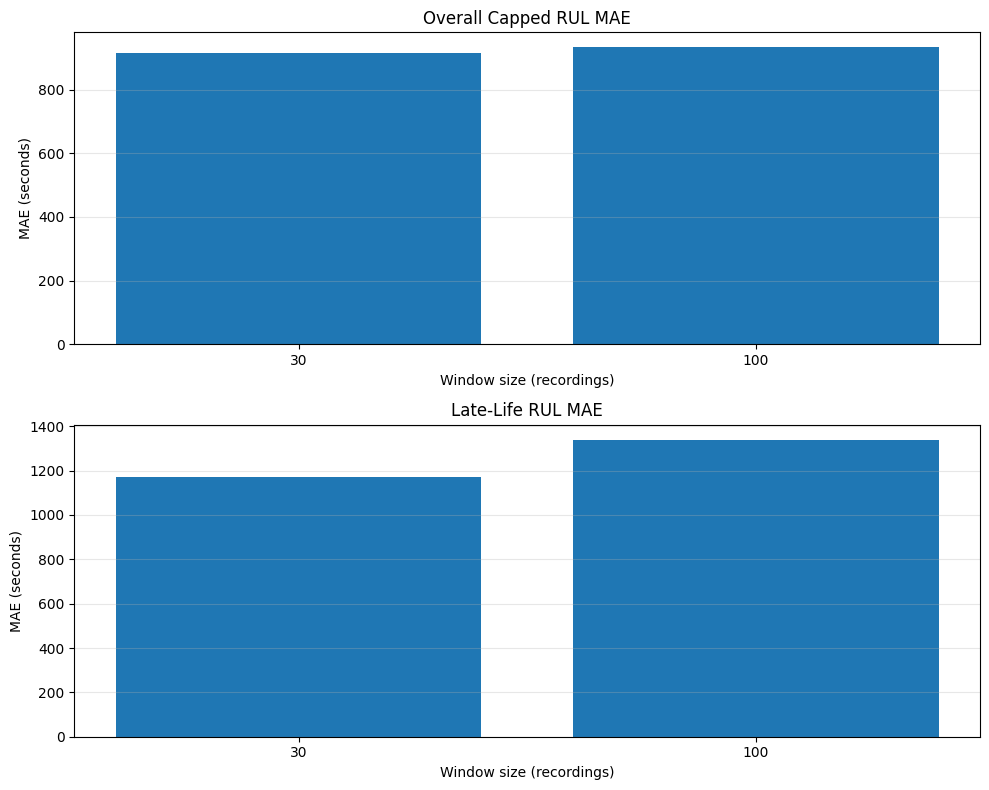

In [ ]:
import gc
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ============================================================
# 1. Configuration
# ============================================================

RUL_CAP = 4000.0
WINDOW_SIZES = [30, 100]
EPOCHS = 8
BATCH_SIZE = 64

tf.keras.utils.set_random_seed(42)

feature_cols = [
    "ch1_rms", "ch1_std", "ch1_mean_abs",
    "ch1_peak", "ch1_ptp", "ch1_kurtosis",
    "ch2_rms", "ch2_std", "ch2_mean_abs",
    "ch2_peak", "ch2_ptp", "ch2_kurtosis"
]

all_data = (
    features_df
    .sort_values(["bearing", "recording_no"])
    .reset_index(drop=True)
)

all_bearings = sorted(all_data["bearing"].unique())

# ============================================================
# 2. Create sequences for a specified window
# ============================================================

def make_windows_for_size(frame, scaled_features, window_size):
    X, y_capped, y_actual = [], [], []

    for _, group in frame.groupby("bearing", sort=False):
        positions = group.index.to_numpy()
        bearing_X = scaled_features[positions]
        bearing_rul = group["RUL_seconds"].to_numpy(dtype=np.float32)

        bearing_capped = np.minimum(bearing_rul, RUL_CAP)

        for end in range(window_size - 1, len(group)):
            start = end - window_size + 1

            X.append(bearing_X[start:end + 1])
            y_capped.append(bearing_capped[end])
            y_actual.append(bearing_rul[end])

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y_capped, dtype=np.float32),
        np.asarray(y_actual, dtype=np.float32)
    )


# ============================================================
# 3. Define the LSTM
# ============================================================

def build_lstm(window_size):
    model = keras.Sequential([
        layers.Input(
            shape=(window_size, len(feature_cols))
        ),
        layers.LSTM(32),
        layers.Dropout(0.2),
        layers.Dense(32, activation="relu"),
        layers.Dense(1, activation="sigmoid")
    ])

    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.0003),
        loss="mse"
    )

    return model


# ============================================================
# 4. Run leave-one-bearing-out validation
# ============================================================

window_results = []
predictions_by_window = {}
actual_by_window = {}
original_by_window = {}

for window_size in WINDOW_SIZES:
    print(f"\n{'=' * 60}")
    print(f"WINDOW SIZE: {window_size} recordings")

    predictions_by_window[window_size] = []
    actual_by_window[window_size] = []
    original_by_window[window_size] = []

    for fold_no, held_out in enumerate(all_bearings, start=1):
        print(f"\nFold {fold_no}/6: {held_out}")

        train_frame = (
            all_data[all_data["bearing"] != held_out]
            .reset_index(drop=True)
        )

        test_frame = (
            all_data[all_data["bearing"] == held_out]
            .reset_index(drop=True)
        )

        # Fit the feature scaler on training bearings only
        scaler = StandardScaler()

        X_train_raw = scaler.fit_transform(
            train_frame[feature_cols]
        )

        X_test_raw = scaler.transform(
            test_frame[feature_cols]
        )

        X_train_seq, y_train_cap, _ = make_windows_for_size(
            train_frame, X_train_raw, window_size
        )

        X_test_seq, y_test_cap, y_test_actual = make_windows_for_size(
            test_frame, X_test_raw, window_size
        )

        # Convert target to [0, 1] for sigmoid output
        y_train_scaled = y_train_cap / RUL_CAP

        keras.backend.clear_session()
        tf.keras.utils.set_random_seed(100 + fold_no)

        model = build_lstm(window_size)

        model.fit(
            X_train_seq,
            y_train_scaled,
            epochs=EPOCHS,
            batch_size=BATCH_SIZE,
            shuffle=True,
            verbose=0
        )

        # Return to seconds and constrain predictions to the target range
        predictions = model.predict(
            X_test_seq, verbose=0
        ).flatten() * RUL_CAP

        predictions = np.clip(predictions, 0, RUL_CAP)

        late_mask = y_test_actual <= RUL_CAP

        mae = mean_absolute_error(y_test_cap, predictions)
        rmse = np.sqrt(mean_squared_error(y_test_cap, predictions))
        late_mae = mean_absolute_error(
            y_test_actual[late_mask],
            predictions[late_mask]
        )

        window_results.append({
            "Window": window_size,
            "Bearing": held_out,
            "Capped MAE (sec)": mae,
            "Capped RMSE (sec)": rmse,
            "Late-life MAE (sec)": late_mae
        })

        predictions_by_window[window_size].append(predictions)
        actual_by_window[window_size].append(y_test_cap)
        original_by_window[window_size].append(y_test_actual)

        print(
            f"MAE={mae:.1f}s | RMSE={rmse:.1f}s | "
            f"Late-life MAE={late_mae:.1f}s"
        )

        del model
        gc.collect()

# ============================================================
# 5. Aggregate results across all six held-out bearings
# ============================================================

window_results_df = pd.DataFrame(window_results)

print("\n=== PER-BEARING RESULTS ===")
display(window_results_df.round(2))

summary_rows = []

for window_size in WINDOW_SIZES:
    actual_cap = np.concatenate(actual_by_window[window_size])
    actual_rul = np.concatenate(original_by_window[window_size])
    predicted = np.concatenate(predictions_by_window[window_size])

    late_mask = actual_rul <= RUL_CAP

    summary_rows.append({
        "Window": window_size,
        "Overall capped MAE (sec)": mean_absolute_error(
            actual_cap, predicted
        ),
        "Overall capped RMSE (sec)": np.sqrt(
            mean_squared_error(actual_cap, predicted)
        ),
        "Capped R2": r2_score(actual_cap, predicted),
        "Late-life MAE (sec)": mean_absolute_error(
            actual_rul[late_mask],
            predicted[late_mask]
        )
    })

window_summary = pd.DataFrame(summary_rows)

print("\n=== WINDOW SIZE COMPARISON ===")
display(window_summary.round(3))

# ============================================================
# 6. Plot results for each window size
# ============================================================

fig, axes = plt.subplots(2, 1, figsize=(10, 8))

axes[0].bar(
    window_summary["Window"].astype(str),
    window_summary["Overall capped MAE (sec)"]
)
axes[0].set_title("Overall Capped RUL MAE")
axes[0].set_xlabel("Window size (recordings)")
axes[0].set_ylabel("MAE (seconds)")
axes[0].grid(axis="y", alpha=0.3)

axes[1].bar(
    window_summary["Window"].astype(str),
    window_summary["Late-life MAE (sec)"]
)
axes[1].set_title("Late-Life RUL MAE")
axes[1].set_xlabel("Window size (recordings)")
axes[1].set_ylabel("MAE (seconds)")
axes[1].grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
import os
import glob
import re
import numpy as np
import pandas as pd

# Existing paths from our notebook
print("Test directory:", TEST_DIR)
print("Full test directory:", VAL_DIR)

def get_acc_files(folder):
    paths = glob.glob(os.path.join(folder, "acc_*.csv"))

    result = {}
    for path in paths:
        match = re.fullmatch(
            r"acc_(\d+)\.csv",
            os.path.basename(path)
        )
        if match:
            result[int(match.group(1))] = path

    return result

verification_results = []

test_bearings = sorted(
    name for name in os.listdir(TEST_DIR)
    if os.path.isdir(os.path.join(TEST_DIR, name))
)

full_bearings = sorted(
    name for name in os.listdir(VAL_DIR)
    if os.path.isdir(os.path.join(VAL_DIR, name))
)

print("\nTest bearings:", len(test_bearings))
print("Full-test bearings:", len(full_bearings))
print("Matching bearing names:", set(test_bearings) == set(full_bearings))

for bearing in test_bearings:
    test_folder = os.path.join(TEST_DIR, bearing)
    full_folder = os.path.join(VAL_DIR, bearing)

    if not os.path.isdir(full_folder):
        print(f"\n{bearing}: missing from Full_Test_Set")
        continue

    test_files = get_acc_files(test_folder)
    full_files = get_acc_files(full_folder)

    test_nums = sorted(test_files)
    full_nums = sorted(full_files)

    common_nums = sorted(set(test_nums) & set(full_nums))

    prefix_numbers_match = (
        test_nums == full_nums[:len(test_nums)]
    )

    # Compare raw contents at beginning, middle and end
    sample_nums = (
        sorted(set([
            test_nums[0],
            test_nums[len(test_nums) // 2],
            test_nums[-1]
        ]))
        if test_nums else []
    )

    sample_contents_match = True

    for number in sample_nums:
        test_df = pd.read_csv(
            test_files[number], header=None
        )
        full_df = pd.read_csv(
            full_files[number], header=None
        )

        if not test_df.equals(full_df):
            sample_contents_match = False

    row = {
        "Bearing": bearing,
        "Test recordings": len(test_nums),
        "Full recordings": len(full_nums),
        "Test last recording": max(test_nums) if test_nums else None,
        "Full last recording": max(full_nums) if full_nums else None,
        "Test numbers are full-set prefix": prefix_numbers_match,
        "Sample contents match": sample_contents_match
    }

    verification_results.append(row)

verification_df = pd.DataFrame(verification_results)

print("\n=== TEST DATA CORRESPONDENCE CHECK ===")
display(verification_df)

Test directory: /content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Test_set/Test_set
Full test directory: /content/bearing_data/extracted/10. FEMTO Bearing/FEMTOBearingDataSet/Validation_Set/Full_Test_Set

Test bearings: 11
Full-test bearings: 11
Matching bearing names: True

=== TEST DATA CORRESPONDENCE CHECK ===


,Bearing,Test recordings,Full recordings,Test last recording,Full last recording,Test numbers are full-set prefix,Sample contents match
0,Bearing1_3,1802,2375,1802,2375,True,True
1,Bearing1_4,1139,1428,1139,1428,True,False
2,Bearing1_5,2302,2463,2302,2463,True,True
3,Bearing1_6,2302,2448,2302,2448,True,True
4,Bearing1_7,1502,2259,1502,2259,True,True
5,Bearing2_3,1202,1955,1202,1955,True,True
6,Bearing2_4,612,751,612,751,True,True
7,Bearing2_5,2002,2311,2002,2311,True,True
8,Bearing2_6,572,701,572,701,True,True
9,Bearing2_7,172,230,172,230,True,True
